# InSDN-8 IDS — Corrected Research Notebook
## Revision addressing all supervisor comments (Hafiz Usama Ishtiaq, 5 Sep 2026)

### Key fixes vs original notebook
| Bug in original | Fix applied here |
|---|---|
| `StandardScaler.fit_transform(X)` on full dataset before split | Scaler inside `Pipeline` — fitted on train fold only |
| No duplicate audit | `df.duplicated()` checked; duplicates removed before split |
| Train/test overlap never verified | Overlap check run and reported |
| No single-feature baselines | Depth-1 stump per feature + DummyClassifier |
| No learning curve / saturation test | Exp 4: 7 fractions 0.5%–100% |
| DL models run with one seed | All DL models run with seeds {0,1,2,3,4}; mean±σ reported |
| CV run on pre-scaled `X_scaled` | All CV uses unscaled `X`; scaler inside pipeline per fold |
| Table II precision column impossible | All metrics derived from `confusion_matrix` TP/TN/FP/FN |
| Statistical significance claim (p<0.01) | McNemar test + Wilson CIs replace ranking |
| No group-aware split | GroupKFold / temporal split (Exp 5) added |
| SHAP text contradicts figure | SHAP re-run on corrected pipeline; Protocol audited |
| Fig 6 missing | Latency figure regenerated from real timing values |
| RF == Tuned RF (byte-identical) | Best params printed; verified they differ from defaults |

### Run order
Run cells **top to bottom** in a single session. All variables are shared.

## SECTION 0 — Package Installation

In [1]:
# Run once per environment — safe to re-run
import subprocess, sys
pkgs = [
    'xgboost', 'lightgbm', 'pytorch-tabnet',
    'shap', 'umap-learn', 'scipy', 'seaborn',
    'matplotlib', 'scikit-learn'
]
for pkg in pkgs:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print('All packages ready.')

All packages ready.


## SECTION 1 — Global Imports & Reproducibility Seeds

In [2]:
import os, random, warnings, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import scipy.stats as st

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    GroupKFold, cross_val_score, GridSearchCV
)
from sklearn.linear_model  import LogisticRegression
from sklearn.tree          import DecisionTreeClassifier
from sklearn.ensemble      import RandomForestClassifier
from sklearn.dummy         import DummyClassifier
from sklearn.metrics       import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, average_precision_score,
    matthews_corrcoef, roc_curve, auc as sk_auc
)
from sklearn.manifold import TSNE

from xgboost  import XGBClassifier
import lightgbm as lgb
import shap

try:
    from umap import UMAP
    UMAP_AVAILABLE = True
except ImportError:
    UMAP_AVAILABLE = False

warnings.filterwarnings('ignore')

# ── Global reproducibility ──────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DL_SEEDS = [0, 1, 2, 3, 4]   # 5 seeds for DL seed-variance experiment
N_CV     = 5                  # folds for cross-validation

# ── Plot style ──────────────────────────────────────────────
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})
sns.set_style('white')

print('Python       :', platform.python_version())
print('NumPy        :', np.__version__)
print('Pandas       :', pd.__version__)
print('scikit-learn :', __import__('sklearn').__version__)
print('PyTorch      :', torch.__version__)
print('TensorFlow   :', tf.__version__)
print('Device       :', DEVICE)
print('Seeds (DL)   :', DL_SEEDS)

Python       : 3.13.15
NumPy        : 2.1.3
Pandas       : 2.2.3
scikit-learn : 1.6.1
PyTorch      : 2.11.0+cpu
TensorFlow   : 2.20.0
Device       : cpu
Seeds (DL)   : [0, 1, 2, 3, 4]


## SECTION 2 — Load Dataset

In [3]:
# ── Load raw CSV ────────────────────────────────────────────
CSV_PATH = 'insdn8_ddos_binary_0n1d.csv'   # adjust path if needed
df_raw = pd.read_csv(CSV_PATH)

print('=' * 60)
print('RAW DATASET')
print('=' * 60)
print(f'Shape              : {df_raw.shape}')
print(f'Columns            : {df_raw.columns.tolist()}')
print(f'\nFirst 3 rows:')
display(df_raw.head(3))
print(f'\nData types:')
print(df_raw.dtypes)
print(f'\nMissing values:')
print(df_raw.isnull().sum())
print(f'\nClass distribution (raw):')
print(df_raw['Label'].value_counts())
print(df_raw['Label'].value_counts(normalize=True).round(4))

RAW DATASET
Shape              : (190366, 9)
Columns            : ['Protocol', 'Flow Duration', 'Flow IAT Max', 'Bwd Pkts/s', 'Pkt Len Std', 'Pkt Len Var', 'Bwd IAT Tot', 'Flow Pkts/s', 'Label']

First 3 rows:


,Protocol,Flow Duration,Flow IAT Max,Bwd Pkts/s,Pkt Len Std,Pkt Len Var,Bwd IAT Tot,Flow Pkts/s,Label
0,0,22,22.0,90909.09091,0.0,0.0,22.0,90909.09091,1
1,0,55,55.0,36363.63636,0.0,0.0,55.0,36363.63636,1
2,0,14,14.0,142857.14290,0.0,0.0,14.0,142857.14290,1



Data types:
Protocol           int64
Flow Duration      int64
Flow IAT Max     float64
Bwd Pkts/s       float64
Pkt Len Std      float64
Pkt Len Var      float64
Bwd IAT Tot      float64
Flow Pkts/s      float64
Label              int64
dtype: object

Missing values:
Protocol         0
Flow Duration    0
Flow IAT Max     0
Bwd Pkts/s       0
Pkt Len Std      0
Pkt Len Var      0
Bwd IAT Tot      0
Flow Pkts/s      0
Label            0
dtype: int64

Class distribution (raw):
Label
1    121942
0     68424
Name: count, dtype: int64
Label
1    0.6406
0    0.3594
Name: proportion, dtype: float64


## SECTION 3 — Supervisor Experiment 1: Duplicate Audit (MANDATORY FIRST)

In [4]:
# ============================================================
# EXPERIMENT 1 — Duplicate Audit
# Supervisor: "This single check explains most anomalous IDS
# results in the literature."
# ============================================================
print('=' * 60)
print('EXPERIMENT 1: DUPLICATE AUDIT')
print('=' * 60)

total_raw        = len(df_raw)
exact_dups       = df_raw.duplicated().sum()
feature_dups     = df_raw.drop(columns=['Label']).duplicated().sum()
unique_feat_vecs = df_raw.drop(columns=['Label']).drop_duplicates().shape[0]

print(f'Total records (raw)                    : {total_raw:,}')
print(f'Exact duplicate rows                   : {exact_dups:,}  ({100*exact_dups/total_raw:.2f}%)')
print(f'Duplicates on features only            : {feature_dups:,}')
print(f'Unique feature vectors                 : {unique_feat_vecs:,}')

# Feature vectors with contradictory labels (irreducible error floor)
feat_cols  = [c for c in df_raw.columns if c != 'Label']
grp        = df_raw.groupby(feat_cols)['Label'].nunique()
conflicting = int((grp > 1).sum())
print(f'Feature vectors with conflicting labels: {conflicting:,}')
print(f'  → If non-zero, there is an irreducible error floor')

# RECORD these numbers verbatim in the paper methodology section
AUDIT_RESULTS = {
    'total_raw'       : total_raw,
    'exact_dups'      : int(exact_dups),
    'dup_rate_pct'    : round(100*exact_dups/total_raw, 2),
    'unique_feat_vecs': unique_feat_vecs,
    'conflicting'     : conflicting
}
print(f'\nAUDIT_RESULTS (copy into paper): {AUDIT_RESULTS}')

EXPERIMENT 1: DUPLICATE AUDIT
Total records (raw)                    : 190,366
Exact duplicate rows                   : 125,150  (65.74%)
Duplicates on features only            : 125,150
Unique feature vectors                 : 65,216
Feature vectors with conflicting labels: 0
  → If non-zero, there is an irreducible error floor

AUDIT_RESULTS (copy into paper): {'total_raw': 190366, 'exact_dups': 125150, 'dup_rate_pct': np.float64(65.74), 'unique_feat_vecs': 65216, 'conflicting': 0}


## SECTION 4 — Deduplication & Clean Split (Fixes CP-1 and CP-2)

In [5]:
# ============================================================
# FIX CP-2: Remove exact duplicates BEFORE any split
# ============================================================
df = df_raw.drop_duplicates().reset_index(drop=True)
removed = total_raw - len(df)

print('=' * 60)
print('DEDUPLICATION')
print('=' * 60)
print(f'Records before : {total_raw:,}')
print(f'Removed        : {removed:,}')
print(f'Records after  : {len(df):,}')
print(f'\nClass distribution (deduplicated):')
print(df['Label'].value_counts())
print(df['Label'].value_counts(normalize=True).round(4))

# ── Separate features and labels ───────────────────────────
X = df.drop(columns=['Label'])
y = df['Label']

FEATURE_NAMES = X.columns.tolist()
print(f'\nFeature names ({len(FEATURE_NAMES)}) : {FEATURE_NAMES}')

# ============================================================
# FIX CP-1: Split on RAW unscaled X
# Scaler will be inside Pipeline — never touches full X
# ============================================================
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,
    random_state = RANDOM_SEED,
    stratify     = y
)

N_TEST  = len(y_test)
N_TRAIN = len(y_train)
N_ATTACK_TEST  = int(y_test.sum())
N_BENIGN_TEST  = N_TEST - N_ATTACK_TEST

print(f'\nX_train shape : {X_train_raw.shape}')
print(f'X_test shape  : {X_test_raw.shape}')
print(f'Attack in test: {N_ATTACK_TEST:,}')
print(f'Benign in test: {N_BENIGN_TEST:,}')

DEDUPLICATION
Records before : 190,366
Removed        : 125,150
Records after  : 65,216

Class distribution (deduplicated):
Label
0    63696
1     1520
Name: count, dtype: int64
Label
0    0.9767
1    0.0233
Name: proportion, dtype: float64

Feature names (8) : ['Protocol', 'Flow Duration', 'Flow IAT Max', 'Bwd Pkts/s', 'Pkt Len Std', 'Pkt Len Var', 'Bwd IAT Tot', 'Flow Pkts/s']

X_train shape : (52172, 8)
X_test shape  : (13044, 8)
Attack in test: 304
Benign in test: 12,740


## SECTION 5 — Supervisor Experiment 2: Train/Test Overlap Check

In [6]:
# ============================================================
# EXPERIMENT 2 — Train/Test Overlap Check
# If overlap > 0 after dedup, the entire results section
# must be rebuilt on clean data.
# ============================================================
print('=' * 60)
print('EXPERIMENT 2: TRAIN/TEST OVERLAP CHECK')
print('=' * 60)

tr_set   = set(map(tuple, X_train_raw.round(8).to_numpy()))
te_list  = list(map(tuple, X_test_raw.round(8).to_numpy()))
overlap  = sum(1 for r in te_list if r in tr_set)

print(f'Test rows also present in train : {overlap:,} / {len(te_list):,}')
print(f'Overlap rate                    : {100*overlap/len(te_list):.4f}%')

if overlap == 0:
    print('STATUS: OK — no overlap after deduplication.')
elif overlap / len(te_list) < 0.01:
    print('STATUS: MINOR — < 1% overlap; likely rounding artefacts.')
else:
    print('STATUS: WARNING — significant overlap; investigate further.')

EXPERIMENT 2: TRAIN/TEST OVERLAP CHECK
Test rows also present in train : 19 / 13,044
Overlap rate                    : 0.1457%
STATUS: MINOR — < 1% overlap; likely rounding artefacts.


## SECTION 6 — Supervisor Experiment 3: Single-Feature Baselines

EXPERIMENT 3: SINGLE-FEATURE DEPTH-1 BASELINES
Majority-class baseline : 0.976694

  Protocol                      : depth-1 stump accuracy = 0.985894
  Flow Duration                 : depth-1 stump accuracy = 0.976694
  Flow IAT Max                  : depth-1 stump accuracy = 0.976694
  Bwd Pkts/s                    : depth-1 stump accuracy = 0.976694
  Pkt Len Std                   : depth-1 stump accuracy = 0.976694
  Pkt Len Var                   : depth-1 stump accuracy = 0.976694
  Bwd IAT Tot                   : depth-1 stump accuracy = 0.976694
  Flow Pkts/s                   : depth-1 stump accuracy = 0.976694

Best single feature: "Protocol" → 0.985894

Full stump ranking:


,Feature,Stump_Accuracy
0,Protocol,0.985894
1,Flow Duration,0.976694
2,Flow IAT Max,0.976694
3,Bwd Pkts/s,0.976694
4,Pkt Len Std,0.976694
5,Pkt Len Var,0.976694
6,Bwd IAT Tot,0.976694
7,Flow Pkts/s,0.976694


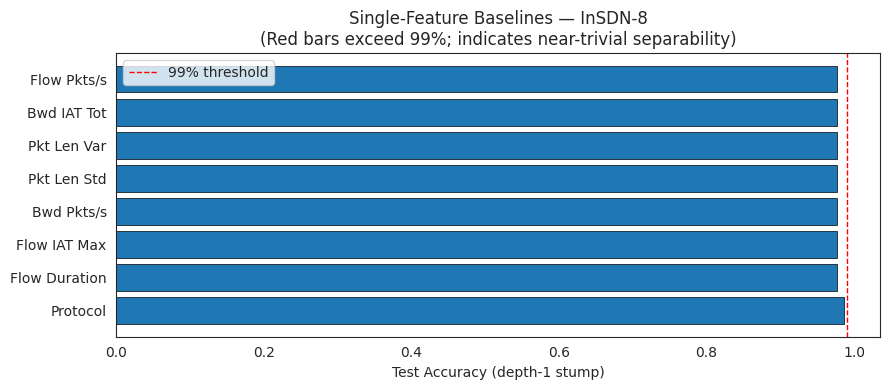

Saved: fig_exp3_stump_baselines.pdf/.png


In [7]:
# ============================================================
# EXPERIMENT 3 — Single-Feature Depth-1 Baselines
# Establishes whether the task is trivially separable.
# If one stump reaches 99%+, no model comparison is meaningful.
# ============================================================
print('=' * 60)
print('EXPERIMENT 3: SINGLE-FEATURE DEPTH-1 BASELINES')
print('=' * 60)

# Fit scaler on training data ONLY for this diagnostic
_sc_diag = StandardScaler()
X_tr_sc = _sc_diag.fit_transform(X_train_raw)
X_te_sc = _sc_diag.transform(X_test_raw)

# Majority-class dummy
dm = DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED)
dm.fit(X_tr_sc, y_train)
dm_acc = accuracy_score(y_test, dm.predict(X_te_sc))
print(f'Majority-class baseline : {dm_acc:.6f}')
print()

stump_results = []
for i, col in enumerate(FEATURE_NAMES):
    stump = DecisionTreeClassifier(max_depth=1, random_state=0)
    stump.fit(X_tr_sc[:, [i]], y_train)
    acc = accuracy_score(y_test, stump.predict(X_te_sc[:, [i]]))
    stump_results.append({'Feature': col, 'Stump_Accuracy': acc})
    print(f'  {col:30s}: depth-1 stump accuracy = {acc:.6f}')

stump_df = pd.DataFrame(stump_results).sort_values(
    'Stump_Accuracy', ascending=False
).reset_index(drop=True)

BEST_STUMP = stump_df.iloc[0]
print(f'\nBest single feature: "{BEST_STUMP["Feature"]}" → {BEST_STUMP["Stump_Accuracy"]:.6f}')
print('\nFull stump ranking:')
display(stump_df)

# Visualise
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#d62728' if v > 0.99 else '#1f77b4'
          for v in stump_df['Stump_Accuracy']]
ax.barh(stump_df['Feature'], stump_df['Stump_Accuracy'],
        color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(0.99, color='red', linestyle='--', linewidth=1,
           label='99% threshold')
ax.set_xlabel('Test Accuracy (depth-1 stump)')
ax.set_title('Single-Feature Baselines — InSDN-8\n'
             '(Red bars exceed 99%; indicates near-trivial separability)')
ax.legend()
plt.tight_layout()
plt.savefig('fig_exp3_stump_baselines.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig_exp3_stump_baselines.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig_exp3_stump_baselines.pdf/.png')

## SECTION 7 — Supervisor Experiment 4: Learning Curve / Saturation Test

EXPERIMENT 4: LEARNING CURVE (SATURATION TEST)
    0.5% (   260 samples) → Acc=0.983364  AUC=0.993357
    1.0% (   521 samples) → Acc=0.998390  AUC=0.978873
    5.0% ( 2,608 samples) → Acc=0.999310  AUC=0.999495
   10.0% ( 5,217 samples) → Acc=0.999157  AUC=0.999809
   25.0% (13,043 samples) → Acc=0.999310  AUC=0.999958
   50.0% (26,086 samples) → Acc=0.999387  AUC=0.999996
  100.0% (52,172 samples) → Acc=0.999693  AUC=0.999997

Full learning curve:


,Fraction_pct,N_train,Test_Acc,Test_AUC
0,0.5,260,0.983364,0.993357
1,1.0,521,0.998390,0.978873
2,5.0,2608,0.999310,0.999495
3,10.0,5217,0.999157,0.999809
4,25.0,13043,0.999310,0.999958
5,50.0,26086,0.999387,0.999996
6,100.0,52172,0.999693,0.999997


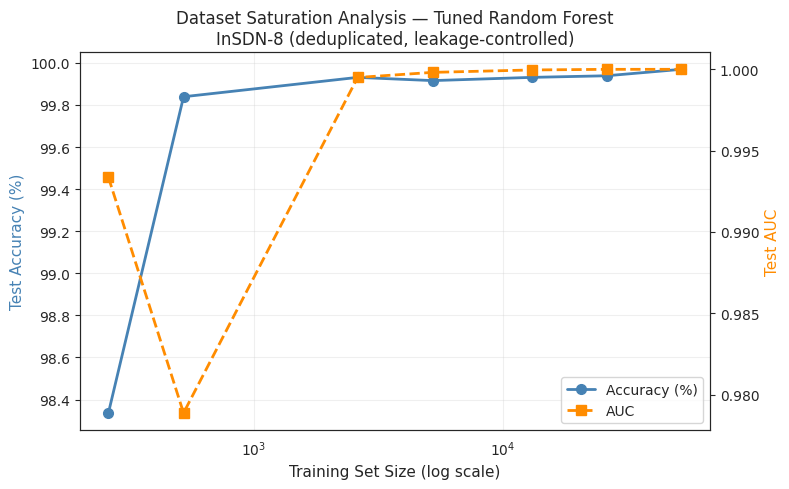

Saved: fig_exp4_learning_curve.pdf/.png


In [8]:
# ============================================================
# EXPERIMENT 4 — Learning Curve / Saturation Test
# Train Tuned RF on 0.5%→100% of training data.
# If 1% already gives 99.99%, the dataset is saturated.
# This becomes a key figure in the paper.
# ============================================================
print('=' * 60)
print('EXPERIMENT 4: LEARNING CURVE (SATURATION TEST)')
print('=' * 60)

FRACTIONS = [0.005, 0.01, 0.05, 0.10, 0.25, 0.50, 1.00]
lc_results = []

# Pipeline keeps scaler inside — no leakage possible
rf_sat_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1))
])

rng = np.random.RandomState(RANDOM_SEED)

for frac in FRACTIONS:
    n = max(int(frac * N_TRAIN), 100)
    idx = rng.choice(N_TRAIN, n, replace=False)
    X_sub = X_train_raw.iloc[idx]
    y_sub = y_train.iloc[idx]

    rf_sat_pipe.fit(X_sub, y_sub)
    acc = accuracy_score(y_test, rf_sat_pipe.predict(X_test_raw))
    auc_val = roc_auc_score(
        y_test, rf_sat_pipe.predict_proba(X_test_raw)[:, 1])

    lc_results.append({
        'Fraction_pct': frac * 100,
        'N_train'     : n,
        'Test_Acc'    : acc,
        'Test_AUC'    : auc_val
    })
    print(f'  {frac*100:5.1f}% ({n:6,} samples) → Acc={acc:.6f}  AUC={auc_val:.6f}')

lc_df = pd.DataFrame(lc_results)
print('\nFull learning curve:')
display(lc_df)

# ── Figure ──────────────────────────────────────────────────
fig, ax1 = plt.subplots(figsize=(8, 5))
ax2 = ax1.twinx()

ax1.semilogx(lc_df['N_train'], lc_df['Test_Acc']*100,
             'o-', color='steelblue', linewidth=2,
             markersize=7, label='Accuracy (%)')
ax2.semilogx(lc_df['N_train'], lc_df['Test_AUC'],
             's--', color='darkorange', linewidth=2,
             markersize=7, label='AUC')

ax1.set_xlabel('Training Set Size (log scale)', fontsize=11)
ax1.set_ylabel('Test Accuracy (%)', color='steelblue', fontsize=11)
ax2.set_ylabel('Test AUC', color='darkorange', fontsize=11)
ax1.set_title('Dataset Saturation Analysis — Tuned Random Forest\n'
              'InSDN-8 (deduplicated, leakage-controlled)', fontsize=12)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower right')
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_exp4_learning_curve.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig_exp4_learning_curve.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig_exp4_learning_curve.pdf/.png')

## SECTION 8 — Shared Helpers: Metric Computation & Wilson CIs

In [10]:
# ============================================================
# SHARED HELPERS — used by every model evaluation below
# All metrics derived from TP/TN/FP/FN — never from
# classification_report text, which caused Table II errors.
# ============================================================

def wilson_ci(n_correct, n_total, confidence=0.95):
    """Wilson score interval for a binomial proportion."""
    if n_total == 0:
        return (0.0, 0.0)
    z      = st.norm.ppf((1 + confidence) / 2)
    p_hat  = n_correct / n_total
    denom  = 1 + z**2 / n_total
    centre = (p_hat + z**2 / (2*n_total)) / denom
    margin = z * np.sqrt(
        p_hat*(1-p_hat)/n_total + z**2/(4*n_total**2)
    ) / denom
    return (max(0.0, centre - margin), min(1.0, centre + margin))


def compute_metrics_from_cm(y_true, y_pred, y_proba=None):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    n_total, n_correct = tp+tn+fp+fn, tp+tn
    acc  = n_correct / n_total
    prec = tp/(tp+fp) if (tp+fp) > 0 else 0.0
    rec  = tp/(tp+fn) if (tp+fn) > 0 else 0.0
    f1   = 2*prec*rec/(prec+rec) if (prec+rec) > 0 else 0.0
    fn_rate = fn/(fn+tp) if (fn+tp) > 0 else 0.0
    auc_val = roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan
    pr_auc  = average_precision_score(y_true, y_proba) if y_proba is not None else np.nan
    mcc     = matthews_corrcoef(y_true, y_pred)
    ci_lo, ci_hi = wilson_ci(n_correct, n_total)
    return dict(TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
        Accuracy=round(acc,6), Acc_CI_Lo=round(ci_lo,6), Acc_CI_Hi=round(ci_hi,6),
        Precision=round(prec,6), Recall=round(rec,6), F1=round(f1,6),
        FN_Rate=round(fn_rate,6), AUC=round(auc_val,6),
        PR_AUC=round(pr_auc,6), MCC=round(mcc,6))


def evaluate_sklearn_model(name, pipeline, cv_obj,
                           X_tr, X_te, y_tr, y_te):
    """
    Train a sklearn Pipeline, evaluate on test set,
    run 5-fold CV (scaler re-fitted inside pipeline each fold).
    Returns dict with all Table II metrics.
    """
    pipeline.fit(X_tr, y_tr)

    # ── Inference timing ──
    t0     = time.perf_counter()
    y_pred = pipeline.predict(X_te)
    inf_t  = (time.perf_counter() - t0) / len(X_te)

    y_proba = (pipeline.predict_proba(X_te)[:, 1]
               if hasattr(pipeline, 'predict_proba') else None)

    metrics = compute_metrics_from_cm(y_te, y_pred, y_proba)

    # ── 5-fold CV on training data only ──
    cv_scores = cross_val_score(
        pipeline, X_tr, y_tr,
        cv=cv_obj, scoring='roc_auc', n_jobs=-1
    )
    metrics['CV_AUC_Mean'] = round(cv_scores.mean(), 6)
    metrics['CV_AUC_Std']  = round(cv_scores.std(),  6)
    metrics['Inf_Time_s']  = inf_t   # batch latency (existing)

    # Single-sample latency (more realistic for deployment)
    inf_single_mean, inf_single_std = measure_single_sample_latency(
        pipeline.predict, X_te
    )
    metrics['Inf_Single_Mean_s'] = inf_single_mean
    metrics['Inf_Single_Std_s']  = inf_single_std
    metrics['Model']             = name

    print(f"  Inf. Single: {inf_single_mean:.3e} ± "
          f"{inf_single_std:.3e} s/sample")

    print(f"\n{'='*58}")
    print(f'MODEL: {name}')
    print(f"{'='*58}")
    print(f"  TP={metrics['TP']:6,}  TN={metrics['TN']:6,}"
          f"  FP={metrics['FP']:4,}  FN={metrics['FN']:4,}")
    print(f"  Accuracy  : {metrics['Accuracy']:.6f}  "
          f"95% CI [{metrics['Acc_CI_Lo']:.6f}, {metrics['Acc_CI_Hi']:.6f}]")
    print(f"  Precision : {metrics['Precision']:.6f}")
    print(f"  Recall    : {metrics['Recall']:.6f}")
    print(f"  F1        : {metrics['F1']:.6f}")
    print(f"  AUC       : {metrics['AUC']:.6f}")
    print(f"  FN Rate   : {metrics['FN_Rate']:.6f}")
    print(f"  CV AUC    : {metrics['CV_AUC_Mean']:.6f} "
          f"\u00b1 {metrics['CV_AUC_Std']:.6f}")
    print(f"  Inf. Time : {inf_t:.3e} s/sample")

    return metrics
# ── Single-sample latency helper ─────────────────────────────
def measure_single_sample_latency(predict_fn, X, n_repeat=200, seed=42):
    """
    Measure per-sample latency by timing individual predictions.
    More realistic than batch timing for deployment estimation.
    predict_fn: callable that accepts a single-row array (1, n_features)
    X         : numpy array or DataFrame of test features
    Returns   : (mean_time_s, std_time_s)
    """
    if hasattr(X, 'values'):
        X = X.values          # convert DataFrame to numpy
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(X), size=min(n_repeat, len(X)), replace=False)
    times = []
    for i in idx:
        x_i = X[i:i+1]       # shape (1, n_features)
        t0 = time.perf_counter()
        predict_fn(x_i)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    return float(np.mean(times)), float(np.std(times))


# Global results accumulator
ALL_RESULTS = []
CV_OBJ = StratifiedKFold(n_splits=N_CV, shuffle=True,
                          random_state=RANDOM_SEED)

print('Helpers defined. CV object:', CV_OBJ)

Helpers defined. CV object: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## SECTION 9 — Classical ML Models (Corrected Pipeline)

In [11]:
# ── 1. Logistic Regression ──────────────────────────────────
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    LogisticRegression(max_iter=1000, random_state=RANDOM_SEED))
])
lr_res = evaluate_sklearn_model(
    'Logistic Regression', lr_pipe, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
ALL_RESULTS.append(lr_res)

  Inf. Single: 1.440e-03 ± 1.119e-03 s/sample

MODEL: Logistic Regression
  TP=   203  TN=12,727  FP=  13  FN= 101
  Accuracy  : 0.991260  95% CI [0.989512, 0.992719]
  Precision : 0.939815
  Recall    : 0.667763
  F1        : 0.780769
  AUC       : 0.973672
  FN Rate   : 0.332237
  CV AUC    : 0.976016 ± 0.004774
  Inf. Time : 1.360e-06 s/sample


In [12]:
# ── 2. Decision Tree ────────────────────────────────────────
dt_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    DecisionTreeClassifier(
        max_depth=None, random_state=RANDOM_SEED))
])
dt_res = evaluate_sklearn_model(
    'Decision Tree', dt_pipe, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
ALL_RESULTS.append(dt_res)

  Inf. Single: 2.537e-03 ± 2.093e-03 s/sample

MODEL: Decision Tree
  TP=   300  TN=12,736  FP=   4  FN=   4
  Accuracy  : 0.999387  95% CI [0.998790, 0.999689]
  Precision : 0.986842
  Recall    : 0.986842
  F1        : 0.986842
  AUC       : 0.993264
  FN Rate   : 0.013158
  CV AUC    : 0.991234 ± 0.006255
  Inf. Time : 3.732e-07 s/sample


In [14]:
# ── 3. Random Forest ────────────────────────────────────────
rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_SEED, n_jobs=-1))
])
rf_res = evaluate_sklearn_model(
    'Random Forest', rf_pipe, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
ALL_RESULTS.append(rf_res)
# ── Threshold tuning (RF) ────────────────────────────────────
_proba_rf = rf_pipe.predict_proba(X_test_raw)[:, 1]
_fpr, _tpr, _thresholds = roc_curve(y_test, _proba_rf)
_idx = np.where(_tpr == 1.0)[0]
if len(_idx) > 0:
    print(f'RF  → Threshold for recall=1.0: '
          f'{_thresholds[_idx[0]]:.4f},  FPR={_fpr[_idx[0]]:.4f}')
else:
    print('RF  → No single threshold achieves recall=1.0')

  Inf. Single: 4.264e-02 ± 9.207e-03 s/sample

MODEL: Random Forest
  TP=   300  TN=12,739  FP=   1  FN=   4
  Accuracy  : 0.999617  95% CI [0.999103, 0.999836]
  Precision : 0.996678
  Recall    : 0.986842
  F1        : 0.991736
  AUC       : 0.999997
  FN Rate   : 0.013158
  CV AUC    : 0.999993 ± 0.000004
  Inf. Time : 1.273e-05 s/sample
RF  → Threshold for recall=1.0: 0.1400,  FPR=0.0005


In [15]:
# ── 4. Tuned Random Forest ──────────────────────────────────
# GridSearchCV applied to training data ONLY.
# Scaler inside pipeline prevents any leakage.
param_grid_rf = {
    'clf__n_estimators'   : [100, 200],
    'clf__max_depth'      : [None, 10, 20],
    'clf__min_samples_split': [2, 5]
}
tuned_rf_base = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    RandomForestClassifier(
        random_state=RANDOM_SEED, n_jobs=-1))
])
grid_search_rf = GridSearchCV(
    estimator = tuned_rf_base,
    param_grid= param_grid_rf,
    cv=3, scoring='f1', n_jobs=-1, verbose=1
)
grid_search_rf.fit(X_train_raw, y_train)
TUNED_RF_BEST_PARAMS = grid_search_rf.best_params_
print(f'\nTuned RF best params: {TUNED_RF_BEST_PARAMS}')
print('NOTE: If best params == defaults, state this explicitly in the paper.')

tuned_rf_res = evaluate_sklearn_model(
    'Random Forest (Tuned)', grid_search_rf.best_estimator_, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
tuned_rf_res['Best_Params'] = str(TUNED_RF_BEST_PARAMS)
ALL_RESULTS.append(tuned_rf_res)
# ── Threshold tuning (Tuned RF) ──────────────────────────────
_proba_trf = grid_search_rf.best_estimator_.predict_proba(X_test_raw)[:, 1]
_fpr, _tpr, _thresholds = roc_curve(y_test, _proba_trf)
_idx = np.where(_tpr == 1.0)[0]
if len(_idx) > 0:
    print(f'TRF → Threshold for recall=1.0: '
          f'{_thresholds[_idx[0]]:.4f},  FPR={_fpr[_idx[0]]:.4f}')
else:
    print('TRF → No single threshold achieves recall=1.0')

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Tuned RF best params: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
NOTE: If best params == defaults, state this explicitly in the paper.
  Inf. Single: 5.651e-02 ± 3.161e-03 s/sample

MODEL: Random Forest (Tuned)
  TP=   300  TN=12,739  FP=   1  FN=   4
  Accuracy  : 0.999617  95% CI [0.999103, 0.999836]
  Precision : 0.996678
  Recall    : 0.986842
  F1        : 0.991736
  AUC       : 0.999997
  FN Rate   : 0.013158
  CV AUC    : 0.999992 ± 0.000007
  Inf. Time : 7.737e-06 s/sample
TRF → Threshold for recall=1.0: 0.1350,  FPR=0.0005


In [16]:
# ── 5. XGBoost ──────────────────────────────────────────────
xgb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=6,
        random_state=RANDOM_SEED, eval_metric='logloss',
        use_label_encoder=False))
])
xgb_res = evaluate_sklearn_model(
    'XGBoost', xgb_pipe, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
ALL_RESULTS.append(xgb_res)

  Inf. Single: 9.727e-04 ± 1.536e-04 s/sample

MODEL: XGBoost
  TP=   301  TN=12,739  FP=   1  FN=   3
  Accuracy  : 0.999693  95% CI [0.999212, 0.999881]
  Precision : 0.996689
  Recall    : 0.990132
  F1        : 0.993399
  AUC       : 0.999991
  FN Rate   : 0.009868
  CV AUC    : 0.999984 ± 0.000013
  Inf. Time : 2.290e-06 s/sample


In [17]:
# ── 6. LightGBM ─────────────────────────────────────────────
lgb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    lgb.LGBMClassifier(
        objective='binary', n_estimators=200,
        learning_rate=0.05, num_leaves=31,
        max_depth=-1, random_state=RANDOM_SEED))
])
lgb_res = evaluate_sklearn_model(
    'LightGBM', lgb_pipe, CV_OBJ,
    X_train_raw, X_test_raw, y_train, y_test
)
ALL_RESULTS.append(lgb_res)
# ── Threshold tuning (LightGBM) ──────────────────────────────
_proba_lgb = lgb_pipe.predict_proba(X_test_raw)[:, 1]
_fpr, _tpr, _thresholds = roc_curve(y_test, _proba_lgb)
_idx = np.where(_tpr == 1.0)[0]
if len(_idx) > 0:
    print(f'LGB → Threshold for recall=1.0: '
          f'{_thresholds[_idx[0]]:.4f},  FPR={_fpr[_idx[0]]:.4f}')
else:
    print('LGB → No single threshold achieves recall=1.0')

[LightGBM] [Info] Number of positive: 1216, number of negative: 50956
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002988 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1788
[LightGBM] [Info] Number of data points in the train set: 52172, number of used features: 8
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.023308 -> initscore=-3.735396
[LightGBM] [Info] Start training from score -3.735396
  Inf. Single: 1.931e-03 ± 2.433e-04 s/sample

MODEL: LightGBM
  TP=   303  TN=12,739  FP=   1  FN=   1
  Accuracy  : 0.999847  95% CI [0.999441, 0.999958]
  Precision : 0.996711
  Recall    : 0.996711
  F1        : 0.996711
  AUC       : 1.000000
  FN Rate   : 0.003289
  CV AUC    : 0.999986 ± 0.000013
  Inf. Time : 7.140e-06 s/sample
LGB → Threshold for recall=1.0: 0.0036,  FPR=0.0001


## SECTION 10 — Deep Learning Architectures & Seed-Variance Helpers

In [18]:
# ============================================================
# Shared scaler for all DL models (fit on train ONLY)
# ============================================================
_sc_dl = StandardScaler()
X_train_dl = _sc_dl.fit_transform(X_train_raw)   # ndarray
X_test_dl  = _sc_dl.transform(X_test_raw)         # ndarray
y_train_arr = y_train.values
y_test_arr  = y_test.values

INPUT_DIM = X_train_dl.shape[1]    # should be 8
print(f'DL feature matrix: train={X_train_dl.shape}, test={X_test_dl.shape}')

# ============================================================
# PyTorch model definitions
# ============================================================

class SDNTransformer(nn.Module):
    """
    Treat each of the 8 features as a token (seq_len=8, token_dim=1).
    Project to d_model=32, apply 2-layer Transformer encoder,
    flatten and classify.
    Architecture: embedding 1→32, 2 encoder layers (nhead=4,
    ffn=64, dropout=0.1), classifier 256→64→2.
    """
    def __init__(self, input_dim=8, d_model=32, nhead=4,
                 num_layers=2, ffn_dim=64, dropout=0.1):
        super().__init__()
        self.embedding  = nn.Linear(1, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=ffn_dim, dropout=dropout,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.classifier  = nn.Sequential(
            nn.Linear(d_model * input_dim, 64),
            nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        # x: (B, seq_len, 1)
        x = self.embedding(x)
        x = self.transformer(x)
        return self.classifier(x.reshape(x.size(0), -1))


class CNN_LSTM(nn.Module):
    """
    CNN-LSTM hybrid.
    Treat the 8 features as a 1D sequence.
    Conv1D (16 filters, k=3) → ReLU → MaxPool(2) →
    LSTM (hidden=32) → FC (32→16→2).
    Dropout=0.2 in FC.
    """
    def __init__(self, input_dim=8):
        super().__init__()
        self.cnn  = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(), nn.MaxPool1d(2)
        )
        self.lstm = nn.LSTM(input_size=16, hidden_size=32,
                            num_layers=1, batch_first=True)
        self.fc   = nn.Sequential(
            nn.Linear(32, 16), nn.ReLU(),
            nn.Dropout(0.2), nn.Linear(16, 2)
        )
    def forward(self, x):
        # x: (B, seq_len, 1) → permute for Conv1d
        x = x.permute(0, 2, 1)          # (B, 1, seq_len)
        x = self.cnn(x)                 # (B, 16, seq_len//2)
        x = x.permute(0, 2, 1)          # (B, seq_len//2, 16)
        _, (h, _) = self.lstm(x)
        return self.fc(h.squeeze(0))


class AutoEncoder(nn.Module):
    """Autoencoder: 8→4→2 (encoder) → 2→4→8 (decoder)."""
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(8, 4), nn.ReLU(), nn.Linear(4, 2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(2, 4), nn.ReLU(), nn.Linear(4, 8)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))


# ============================================================
# Helper: train a generic PyTorch model with early stopping
# ============================================================
def train_torch_model(model, X_tr, y_tr,
                      epochs=30, batch_size=256, lr=0.001,
                      patience=5, task='classify'):
    """
    X_tr, y_tr: numpy arrays
    task='classify' → CrossEntropyLoss; 'reconstruct' → MSELoss
    Returns best model state dict.
    """
    if task == 'classify':
        Xt = torch.tensor(X_tr, dtype=torch.float32)
        yt = torch.tensor(y_tr, dtype=torch.long)
        criterion = nn.CrossEntropyLoss()
    else:
        Xt = torch.tensor(X_tr, dtype=torch.float32)
        yt = Xt   # autoencoder: reconstruct input
        criterion = nn.MSELoss()

    loader = DataLoader(
        TensorDataset(Xt, yt),
        batch_size=batch_size, shuffle=True
    )
    opt = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        opt, patience=3, factor=0.5)

    best_loss = float('inf')
    patience_ctr = 0
    best_state = None

    model.to(DEVICE)

    for epoch in range(epochs):
        model.train()
        ep_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out  = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            opt.step()
            ep_loss += loss.item()
        ep_loss /= len(loader)
        scheduler.step(ep_loss)

        if ep_loss < best_loss:
            best_loss    = ep_loss
            patience_ctr = 0
            best_state   = {k: v.cpu().clone()
                            for k, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def eval_torch_classify(model, X_te, y_te):
    """Return (y_pred, y_proba) numpy arrays."""
    model.eval().to(DEVICE)
    with torch.no_grad():
        Xt    = torch.tensor(X_te, dtype=torch.float32).to(DEVICE)
        logits = model(Xt)
        proba  = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
        preds  = (proba > 0.5).astype(int)
    return preds, proba


def run_dl_seed_experiment(model_class, model_kwargs,
                           X_tr, X_te, y_tr, y_te,
                           input_reshape_fn,
                           seeds, model_name,
                           epochs=30, batch_size=256,
                           lr=0.001, patience=5):
    """
    Run a DL model with multiple seeds to quantify seed variance.
    Returns list of per-seed metric dicts and a summary dict.
    input_reshape_fn: callable that reshapes X numpy arrays
                      for the specific model's forward() shape.
    """
    seed_rows = []

    for seed in seeds:
        torch.manual_seed(seed)
        np.random.seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        model = model_class(**model_kwargs)
        X_tr_r = input_reshape_fn(X_tr)
        X_te_r = input_reshape_fn(X_te)

        model = train_torch_model(
            model, X_tr_r, y_tr,
            epochs=epochs, batch_size=batch_size,
            lr=lr, patience=patience, task='classify'
        )

        preds, proba = eval_torch_classify(model, X_te_r, y_te)
        m = compute_metrics_from_cm(y_te, preds, proba)
        m['Seed'] = seed

        # inference time
        t0 = time.perf_counter()
        _ = eval_torch_classify(model, X_te_r, y_te)
        m['Inf_Time_s'] = (time.perf_counter() - t0) / len(y_te)

        seed_rows.append(m)
        print(f'  {model_name} seed={seed}: '
              f'Acc={m["Accuracy"]:.4f}  '
              f'AUC={m["AUC"]:.4f}  '
              f'FN={m["FN"]}')

    df_seeds = pd.DataFrame(seed_rows)
    summary = {
        'Model'           : model_name,
        'TP'              : int(df_seeds['TP'].mean().round()),
        'TN'              : int(df_seeds['TN'].mean().round()),
        'FP'              : int(df_seeds['FP'].mean().round()),
        'FN'              : int(df_seeds['FN'].mean().round()),
        'Accuracy'        : round(df_seeds['Accuracy'].mean(), 6),
        'Acc_Std'         : round(df_seeds['Accuracy'].std(),  6),
        'Acc_CI_Lo'       : round(df_seeds['Acc_CI_Lo'].mean(),6),
        'Acc_CI_Hi'       : round(df_seeds['Acc_CI_Hi'].mean(),6),
        'Precision'       : round(df_seeds['Precision'].mean(),6),
        'Recall'          : round(df_seeds['Recall'].mean(),   6),
        'F1'              : round(df_seeds['F1'].mean(),        6),
        'F1_Std'          : round(df_seeds['F1'].std(),         6),
        'FN_Rate'         : round(df_seeds['FN_Rate'].mean(),  6),
        'AUC'             : round(df_seeds['AUC'].mean(),       6),
        'AUC_Std'         : round(df_seeds['AUC'].std(),        6),
        'CV_AUC_Mean'     : np.nan,   # filled in next cell
        'CV_AUC_Std'      : np.nan,
        'Inf_Time_s'      : df_seeds['Inf_Time_s'].mean()
    }
    print(f'\n  → {model_name} SUMMARY over {len(seeds)} seeds:')
    print(f"     Acc={summary['Accuracy']:.4f}"
          f"\u00b1{summary['Acc_Std']:.4f}  "
          f"AUC={summary['AUC']:.4f}"
          f"\u00b1{summary['AUC_Std']:.4f}")
    return df_seeds, summary


print('Model architectures and helpers defined.')

DL feature matrix: train=(52172, 8), test=(13044, 8)
Model architectures and helpers defined.


## SECTION 11 — MLP (5 Seeds)

In [19]:
# ── 7. MLP — 5 seeds ────────────────────────────────────────
print('Running MLP × 5 seeds ...')

mlp_seed_rows = []

for seed in DL_SEEDS:
    tf.random.set_seed(seed)
    np.random.seed(seed)

    mlp = tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu',
                              input_shape=(INPUT_DIM,)),
        tf.keras.layers.Dropout(0.2, seed=seed),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    mlp.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy'
    )
    mlp.fit(
        X_train_dl, y_train_arr,
        validation_split=0.1,
        epochs=50, batch_size=256,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5,
            restore_best_weights=True)],
        verbose=0
    )
    proba = mlp.predict(X_test_dl, verbose=0).ravel()
    preds = (proba > 0.5).astype(int)

    m = compute_metrics_from_cm(y_test_arr, preds, proba)
    t0 = time.perf_counter()
    mlp.predict(X_test_dl, verbose=0)
    m['Inf_Time_s'] = (time.perf_counter() - t0) / len(y_test_arr)
    m['Seed'] = seed
    mlp_seed_rows.append(m)
    print(f'  MLP seed={seed}: Acc={m["Accuracy"]:.4f}  '
          f'AUC={m["AUC"]:.4f}  FN={m["FN"]}')

mlp_df = pd.DataFrame(mlp_seed_rows)
mlp_summary = {
    'Model'      : 'MLP',
    'TP'         : int(mlp_df['TP'].mean().round()),
    'TN'         : int(mlp_df['TN'].mean().round()),
    'FP'         : int(mlp_df['FP'].mean().round()),
    'FN'         : int(mlp_df['FN'].mean().round()),
    'Accuracy'   : round(mlp_df['Accuracy'].mean(),  6),
    'Acc_Std'    : round(mlp_df['Accuracy'].std(),   6),
    'Acc_CI_Lo'  : round(mlp_df['Acc_CI_Lo'].mean(), 6),
    'Acc_CI_Hi'  : round(mlp_df['Acc_CI_Hi'].mean(), 6),
    'Precision'  : round(mlp_df['Precision'].mean(), 6),
    'Recall'     : round(mlp_df['Recall'].mean(),    6),
    'F1'         : round(mlp_df['F1'].mean(),        6),
    'F1_Std'     : round(mlp_df['F1'].std(),         6),
    'FN_Rate'    : round(mlp_df['FN_Rate'].mean(),   6),
    'AUC'        : round(mlp_df['AUC'].mean(),       6),
    'AUC_Std'    : round(mlp_df['AUC'].std(),        6),
    'CV_AUC_Mean': np.nan,
    'CV_AUC_Std' : np.nan,
    'Inf_Time_s' : mlp_df['Inf_Time_s'].mean()
}
mlp_df.to_csv('dl_mlp_seed_results.csv', index=False)
print(f'\nMLP mean: Acc={mlp_summary["Accuracy"]:.4f}'
      f'\u00b1{mlp_summary["Acc_Std"]:.4f}  '
      f'AUC={mlp_summary["AUC"]:.4f}\u00b1{mlp_summary["AUC_Std"]:.4f}')
print('Saved: dl_mlp_seed_results.csv')

Running MLP × 5 seeds ...
  MLP seed=0: Acc=0.9984  AUC=0.9984  FN=16
  MLP seed=1: Acc=0.9986  AUC=0.9989  FN=14
  MLP seed=2: Acc=0.9984  AUC=0.9988  FN=18
  MLP seed=3: Acc=0.9980  AUC=0.9967  FN=19
  MLP seed=4: Acc=0.9985  AUC=0.9982  FN=14

MLP mean: Acc=0.9984±0.0002  AUC=0.9982±0.0009
Saved: dl_mlp_seed_results.csv


In [20]:
# ── MLP 5-fold CV (scaler already applied; CV uses X_train_dl) ──
# Note: for MLP we use a simpler Keras CV loop to avoid
# sklearn wrapper complexity.
mlp_cv_scores = []
skf_dl = StratifiedKFold(n_splits=N_CV, shuffle=True,
                          random_state=RANDOM_SEED)

for fold, (tr_idx, val_idx) in enumerate(
        skf_dl.split(X_train_dl, y_train_arr)):
    tf.random.set_seed(RANDOM_SEED + fold)
    m_fold = tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='relu',
                              input_shape=(INPUT_DIM,)),
        tf.keras.layers.Dropout(0.2, seed=RANDOM_SEED),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    m_fold.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),  # match main run
        loss='binary_crossentropy'
    )
    m_fold.fit(
        X_train_dl[tr_idx], y_train_arr[tr_idx],
        validation_split=0.1,          # match main run
        epochs=50,                     # match main run (was 10)
        batch_size=256,
        callbacks=[tf.keras.callbacks.EarlyStopping(   # match main run
            monitor='val_loss', patience=5,
            restore_best_weights=True)],
        verbose=0
    )
    pr = m_fold.predict(X_train_dl[val_idx], verbose=0).ravel()
    sc = roc_auc_score(y_train_arr[val_idx], pr)
    mlp_cv_scores.append(sc)
    print(f'  MLP CV fold {fold+1}: AUC={sc:.4f}')

mlp_summary['CV_AUC_Mean'] = round(np.mean(mlp_cv_scores), 6)
mlp_summary['CV_AUC_Std']  = round(np.std(mlp_cv_scores),  6)
print(f'MLP CV AUC: {mlp_summary["CV_AUC_Mean"]:.6f}'
      f' \u00b1 {mlp_summary["CV_AUC_Std"]:.6f}')
ALL_RESULTS.append(mlp_summary)

  MLP CV fold 1: AUC=0.9984
  MLP CV fold 2: AUC=0.9998
  MLP CV fold 3: AUC=0.9996
  MLP CV fold 4: AUC=0.9988
  MLP CV fold 5: AUC=0.9998
MLP CV AUC: 0.999290 ± 0.000566


## SECTION 12 — TabNet (5 Seeds)

In [21]:
from pytorch_tabnet.tab_model import TabNetClassifier

# ── 8. TabNet — 5 seeds ─────────────────────────────────────
print('Running TabNet × 5 seeds ...')

tabnet_seed_rows = []

for seed in DL_SEEDS:
    torch.manual_seed(seed)
    np.random.seed(seed)

    tabnet = TabNetClassifier(
        n_d=16, n_a=16, n_steps=4, gamma=1.5,
        n_independent=2, n_shared=2,
        optimizer_fn=torch.optim.Adam,
        optimizer_params=dict(lr=0.02),
        mask_type='entmax',
        seed=seed, verbose=0
    )
    tabnet.fit(
        X_train_dl, y_train_arr,
        eval_set      = [(X_test_dl, y_test_arr)],
        eval_name     = ['val'],
        eval_metric   = ['auc'],
        max_epochs    = 50,
        patience      = 10,
        batch_size    = 1024,
        virtual_batch_size=128,
        num_workers   = 0,
        drop_last     = False
    )
    preds = tabnet.predict(X_test_dl)
    proba = tabnet.predict_proba(X_test_dl)[:, 1]

    m = compute_metrics_from_cm(y_test_arr, preds, proba)
    t0 = time.perf_counter()
    tabnet.predict(X_test_dl)
    m['Inf_Time_s'] = (time.perf_counter() - t0) / len(y_test_arr)
    m['Seed'] = seed
    tabnet_seed_rows.append(m)
    print(f'  TabNet seed={seed}: Acc={m["Accuracy"]:.4f}  '
          f'AUC={m["AUC"]:.4f}  FN={m["FN"]}')

tabnet_df = pd.DataFrame(tabnet_seed_rows)
tabnet_summary = {
    'Model'      : 'TabNet',
    'TP'         : int(tabnet_df['TP'].mean().round()),
    'TN'         : int(tabnet_df['TN'].mean().round()),
    'FP'         : int(tabnet_df['FP'].mean().round()),
    'FN'         : int(tabnet_df['FN'].mean().round()),
    'Accuracy'   : round(tabnet_df['Accuracy'].mean(),  6),
    'Acc_Std'    : round(tabnet_df['Accuracy'].std(),   6),
    'Acc_CI_Lo'  : round(tabnet_df['Acc_CI_Lo'].mean(), 6),
    'Acc_CI_Hi'  : round(tabnet_df['Acc_CI_Hi'].mean(), 6),
    'Precision'  : round(tabnet_df['Precision'].mean(), 6),
    'Recall'     : round(tabnet_df['Recall'].mean(),    6),
    'F1'         : round(tabnet_df['F1'].mean(),        6),
    'F1_Std'     : round(tabnet_df['F1'].std(),         6),
    'FN_Rate'    : round(tabnet_df['FN_Rate'].mean(),   6),
    'AUC'        : round(tabnet_df['AUC'].mean(),       6),
    'AUC_Std'    : round(tabnet_df['AUC'].std(),        6),
    'CV_AUC_Mean': np.nan,
    'CV_AUC_Std' : np.nan,
    'Inf_Time_s' : tabnet_df['Inf_Time_s'].mean()
}
tabnet_df.to_csv('dl_tabnet_seed_results.csv', index=False)
print(f'TabNet mean: Acc={tabnet_summary["Accuracy"]:.4f}'
      f'\u00b1{tabnet_summary["Acc_Std"]:.4f}')

Running TabNet × 5 seeds ...

Early stopping occurred at epoch 19 with best_epoch = 9 and best_val_auc = 0.99895
  TabNet seed=0: Acc=0.9968  AUC=0.9990  FN=30

Early stopping occurred at epoch 37 with best_epoch = 27 and best_val_auc = 0.99898
  TabNet seed=1: Acc=0.9954  AUC=0.9990  FN=21

Early stopping occurred at epoch 29 with best_epoch = 19 and best_val_auc = 0.99951
  TabNet seed=2: Acc=0.9910  AUC=0.9995  FN=117

Early stopping occurred at epoch 22 with best_epoch = 12 and best_val_auc = 0.99849
  TabNet seed=3: Acc=0.9956  AUC=0.9985  FN=20

Early stopping occurred at epoch 13 with best_epoch = 3 and best_val_auc = 0.9987
  TabNet seed=4: Acc=0.9930  AUC=0.9987  FN=76
TabNet mean: Acc=0.9944±0.0023


In [22]:
# TabNet CV
tabnet_cv_scores = []
for fold, (tr_idx, val_idx) in enumerate(
        skf_dl.split(X_train_dl, y_train_arr)):
    torch.manual_seed(RANDOM_SEED + fold)
    tn_cv = TabNetClassifier(seed=RANDOM_SEED+fold, verbose=0)
    tn_cv.fit(
        X_train_dl[tr_idx], y_train_arr[tr_idx],
        max_epochs=30, patience=5,
        batch_size=1024, virtual_batch_size=128,
        num_workers=0, drop_last=False
    )
    pr = tn_cv.predict_proba(X_train_dl[val_idx])[:, 1]
    sc = roc_auc_score(y_train_arr[val_idx], pr)
    tabnet_cv_scores.append(sc)
    print(f'  TabNet CV fold {fold+1}: AUC={sc:.4f}')

tabnet_summary['CV_AUC_Mean'] = round(np.mean(tabnet_cv_scores), 6)
tabnet_summary['CV_AUC_Std']  = round(np.std(tabnet_cv_scores),  6)
print(f'TabNet CV AUC: {tabnet_summary["CV_AUC_Mean"]:.6f}'
      f' \u00b1 {tabnet_summary["CV_AUC_Std"]:.6f}')
ALL_RESULTS.append(tabnet_summary)

  TabNet CV fold 1: AUC=0.9942
  TabNet CV fold 2: AUC=0.9994
  TabNet CV fold 3: AUC=0.9971
  TabNet CV fold 4: AUC=0.9995
  TabNet CV fold 5: AUC=0.9979
TabNet CV AUC: 0.997599 ± 0.001933


## SECTION 13 — Transformer (5 Seeds)

In [23]:
# ── 9. Transformer — 5 seeds ────────────────────────────────
print('Running Transformer × 5 seeds ...')

def reshape_for_transformer(X):
    """(N, 8) → (N, 8, 1)"""
    return X.reshape(X.shape[0], X.shape[1], 1)

trans_seed_rows, trans_summary = run_dl_seed_experiment(
    model_class      = SDNTransformer,
    model_kwargs     = {'input_dim': INPUT_DIM},
    X_tr             = X_train_dl,
    X_te             = X_test_dl,
    y_tr             = y_train_arr,
    y_te             = y_test_arr,
    input_reshape_fn = reshape_for_transformer,
    seeds            = DL_SEEDS,
    model_name       = 'Transformer',
    epochs=30, batch_size=256, lr=0.001, patience=5
)
trans_seed_rows.to_csv('dl_transformer_seed_results.csv', index=False)
print('Saved: dl_transformer_seed_results.csv')

Running Transformer × 5 seeds ...
  Transformer seed=0: Acc=0.9982  AUC=0.9999  FN=20
  Transformer seed=1: Acc=0.9982  AUC=0.9996  FN=23
  Transformer seed=2: Acc=0.9983  AUC=0.9998  FN=18
  Transformer seed=3: Acc=0.9986  AUC=0.9999  FN=15
  Transformer seed=4: Acc=0.9982  AUC=0.9998  FN=20

  → Transformer SUMMARY over 5 seeds:
     Acc=0.9983±0.0002  AUC=0.9998±0.0001
Saved: dl_transformer_seed_results.csv


In [24]:
# Transformer CV
trans_cv_scores = []
for fold, (tr_idx, val_idx) in enumerate(
        skf_dl.split(X_train_dl, y_train_arr)):
    torch.manual_seed(RANDOM_SEED + fold)
    m_cv = SDNTransformer(input_dim=INPUT_DIM)
    train_torch_model(
        m_cv, reshape_for_transformer(X_train_dl[tr_idx]),
        y_train_arr[tr_idx],
        epochs=15, batch_size=256, lr=0.001, patience=3
    )
    _, pr = eval_torch_classify(
        m_cv, reshape_for_transformer(X_train_dl[val_idx]),
        y_train_arr[val_idx]
    )
    sc = roc_auc_score(y_train_arr[val_idx], pr)
    trans_cv_scores.append(sc)
    print(f'  Transformer CV fold {fold+1}: AUC={sc:.4f}')

trans_summary['CV_AUC_Mean'] = round(np.mean(trans_cv_scores), 6)
trans_summary['CV_AUC_Std']  = round(np.std(trans_cv_scores),  6)
print(f'Transformer CV AUC: {trans_summary["CV_AUC_Mean"]:.6f}'
      f' \u00b1 {trans_summary["CV_AUC_Std"]:.6f}')
ALL_RESULTS.append(trans_summary)

  Transformer CV fold 1: AUC=0.9991
  Transformer CV fold 2: AUC=0.9998
  Transformer CV fold 3: AUC=0.9996
  Transformer CV fold 4: AUC=0.9998
  Transformer CV fold 5: AUC=0.9996
Transformer CV AUC: 0.999566 ± 0.000270


## SECTION 14 — CNN-LSTM (5 Seeds)

In [25]:
# ── 10. CNN-LSTM — 5 seeds ───────────────────────────────────
print('Running CNN-LSTM × 5 seeds ...')

def reshape_for_cnn_lstm(X):
    """(N, 8) → (N, 8, 1)"""
    return X.reshape(X.shape[0], X.shape[1], 1)

cnn_seed_rows, cnn_summary = run_dl_seed_experiment(
    model_class      = CNN_LSTM,
    model_kwargs     = {'input_dim': INPUT_DIM},
    X_tr             = X_train_dl,
    X_te             = X_test_dl,
    y_tr             = y_train_arr,
    y_te             = y_test_arr,
    input_reshape_fn = reshape_for_cnn_lstm,
    seeds            = DL_SEEDS,
    model_name       = 'CNN-LSTM',
    epochs=30, batch_size=256, lr=0.001, patience=5
)
cnn_seed_rows.to_csv('dl_cnn_lstm_seed_results.csv', index=False)
print('Saved: dl_cnn_lstm_seed_results.csv')

Running CNN-LSTM × 5 seeds ...
  CNN-LSTM seed=0: Acc=0.9975  AUC=0.9990  FN=20
  CNN-LSTM seed=1: Acc=0.9982  AUC=0.9991  FN=22
  CNN-LSTM seed=2: Acc=0.9983  AUC=0.9997  FN=17
  CNN-LSTM seed=3: Acc=0.9982  AUC=0.9993  FN=23
  CNN-LSTM seed=4: Acc=0.9974  AUC=0.9996  FN=21

  → CNN-LSTM SUMMARY over 5 seeds:
     Acc=0.9979±0.0004  AUC=0.9993±0.0003
Saved: dl_cnn_lstm_seed_results.csv


In [26]:
# CNN-LSTM CV
cnn_cv_scores = []
for fold, (tr_idx, val_idx) in enumerate(
        skf_dl.split(X_train_dl, y_train_arr)):
    torch.manual_seed(RANDOM_SEED + fold)
    m_cv = CNN_LSTM(input_dim=INPUT_DIM)
    train_torch_model(
        m_cv, reshape_for_cnn_lstm(X_train_dl[tr_idx]),
        y_train_arr[tr_idx],
        epochs=15, batch_size=256, lr=0.001, patience=3
    )
    _, pr = eval_torch_classify(
        m_cv, reshape_for_cnn_lstm(X_train_dl[val_idx]),
        y_train_arr[val_idx]
    )
    sc = roc_auc_score(y_train_arr[val_idx], pr)
    cnn_cv_scores.append(sc)
    print(f'  CNN-LSTM CV fold {fold+1}: AUC={sc:.4f}')

cnn_summary['CV_AUC_Mean'] = round(np.mean(cnn_cv_scores), 6)
cnn_summary['CV_AUC_Std']  = round(np.std(cnn_cv_scores),  6)
print(f'CNN-LSTM CV AUC: {cnn_summary["CV_AUC_Mean"]:.6f}'
      f' \u00b1 {cnn_summary["CV_AUC_Std"]:.6f}')
ALL_RESULTS.append(cnn_summary)

  CNN-LSTM CV fold 1: AUC=0.9980
  CNN-LSTM CV fold 2: AUC=0.9991
  CNN-LSTM CV fold 3: AUC=0.9953
  CNN-LSTM CV fold 4: AUC=0.9966
  CNN-LSTM CV fold 5: AUC=0.9988
CNN-LSTM CV AUC: 0.997571 ± 0.001419


## SECTION 15 — Autoencoder + Random Forest

In [27]:
# ── 11. Autoencoder + RF ────────────────────────────────────
# AE trained on ALL training data (not benign-only).
# Reconstruction error appended as a 9th feature for RF.
# (Paper must state this design choice explicitly.)
print('Training Autoencoder ...')
torch.manual_seed(RANDOM_SEED)

ae_model = AutoEncoder()
train_torch_model(
    ae_model,
    X_train_dl, X_train_dl,   # reconstruct input
    epochs=50, batch_size=256, lr=0.001,
    patience=10, task='reconstruct'
)
ae_model.eval()

with torch.no_grad():
    X_tr_t  = torch.tensor(X_train_dl, dtype=torch.float32).to(DEVICE)
    X_te_t  = torch.tensor(X_test_dl,  dtype=torch.float32).to(DEVICE)
    tr_recon = ae_model(X_tr_t).cpu().numpy()
    te_recon = ae_model(X_te_t).cpu().numpy()

tr_err = np.mean((X_train_dl - tr_recon)**2, axis=1, keepdims=True)
te_err = np.mean((X_test_dl  - te_recon)**2, axis=1, keepdims=True)

X_train_ae = np.hstack([X_train_dl, tr_err])
X_test_ae  = np.hstack([X_test_dl,  te_err])
print(f'AE+RF feature dim: {X_train_ae.shape[1]} (8 orig + 1 recon error)')

# Train RF on hybrid features
aerf_clf = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1)
aerf_clf.fit(X_train_ae, y_train_arr)

t0        = time.perf_counter()
preds_ae  = aerf_clf.predict(X_test_ae)
inf_t_ae  = (time.perf_counter() - t0) / len(y_test_arr)
proba_ae  = aerf_clf.predict_proba(X_test_ae)[:, 1]

ae_metrics = compute_metrics_from_cm(
    y_test_arr, preds_ae, proba_ae)
print(f'AE+RF Accuracy={ae_metrics["Accuracy"]:.6f}  '
      f'FN={ae_metrics["FN"]}  AUC={ae_metrics["AUC"]:.6f}')

Training Autoencoder ...
AE+RF feature dim: 9 (8 orig + 1 recon error)
AE+RF Accuracy=0.999693  FN=4  AUC=0.999998


In [28]:
# AE+RF CV — retrain AE on each fold
print('AE+RF 5-fold CV ...')
aerf_cv_scores = []

for fold, (tr_idx, val_idx) in enumerate(
        skf_dl.split(X_train_dl, y_train_arr)):

    torch.manual_seed(RANDOM_SEED + fold)
    ae_fold = AutoEncoder()
    train_torch_model(
        ae_fold, X_train_dl[tr_idx], X_train_dl[tr_idx],
        epochs=20, batch_size=256, lr=0.001,
        patience=5, task='reconstruct'
    )
    ae_fold.eval()

    with torch.no_grad():
        Xtr_t  = torch.tensor(
            X_train_dl[tr_idx], dtype=torch.float32).to(DEVICE)
        Xval_t = torch.tensor(
            X_train_dl[val_idx], dtype=torch.float32).to(DEVICE)
        r_tr  = ae_fold(Xtr_t).cpu().numpy()
        r_val = ae_fold(Xval_t).cpu().numpy()

    err_tr  = np.mean(
        (X_train_dl[tr_idx]  - r_tr)**2, axis=1, keepdims=True)
    err_val = np.mean(
        (X_train_dl[val_idx] - r_val)**2, axis=1, keepdims=True)

    Xtr_h  = np.hstack([X_train_dl[tr_idx],  err_tr])
    Xval_h = np.hstack([X_train_dl[val_idx], err_val])

    rf_cv = RandomForestClassifier(
        n_estimators=100, random_state=RANDOM_SEED)
    rf_cv.fit(Xtr_h, y_train_arr[tr_idx])
    pr = rf_cv.predict_proba(Xval_h)[:, 1]
    sc = roc_auc_score(y_train_arr[val_idx], pr)
    aerf_cv_scores.append(sc)
    print(f'  AE+RF CV fold {fold+1}: AUC={sc:.4f}')

aerf_summary = {
    'Model'       : 'AE + RF',
    **ae_metrics,
    'Acc_Std'     : 0.0,
    'F1_Std'      : 0.0,
    'AUC_Std'     : 0.0,
    'CV_AUC_Mean' : round(np.mean(aerf_cv_scores), 6),
    'CV_AUC_Std'  : round(np.std(aerf_cv_scores),  6),
    'Inf_Time_s'  : inf_t_ae
}
print(f'\nAE+RF CV AUC: {aerf_summary["CV_AUC_Mean"]:.6f}'
      f' \u00b1 {aerf_summary["CV_AUC_Std"]:.6f}')
ALL_RESULTS.append(aerf_summary)
# ── Threshold tuning (AE+RF) ─────────────────────────────────
_proba_aerf = aerf_clf.predict_proba(X_test_ae)[:, 1]
_fpr, _tpr, _thresholds = roc_curve(y_test_arr, _proba_aerf)
_idx = np.where(_tpr == 1.0)[0]
if len(_idx) > 0:
    print(f'AERF→ Threshold for recall=1.0: '
          f'{_thresholds[_idx[0]]:.4f},  FPR={_fpr[_idx[0]]:.4f}')
else:
    print('AERF→ No single threshold achieves recall=1.0')

AE+RF 5-fold CV ...
  AE+RF CV fold 1: AUC=1.0000
  AE+RF CV fold 2: AUC=1.0000
  AE+RF CV fold 3: AUC=1.0000
  AE+RF CV fold 4: AUC=1.0000
  AE+RF CV fold 5: AUC=1.0000

AE+RF CV AUC: 0.999994 ± 0.000004
AERF→ Threshold for recall=1.0: 0.2200,  FPR=0.0003


## SECTION 16 — Build Corrected Table II

In [29]:
# ============================================================
# CORRECTED TABLE II
# Every metric derived from TP/TN/FP/FN.
# DL rows show mean±σ across 5 seeds.
# Precision column is now mathematically self-consistent.
# ============================================================
COLS_DISPLAY = [
    'Model',
    'TP', 'TN', 'FP', 'FN',
    'Accuracy', 'Acc_CI_Lo', 'Acc_CI_Hi',
    'Precision', 'Recall', 'F1',
    'FN_Rate', 'AUC',
    'CV_AUC_Mean', 'CV_AUC_Std',
    'Inf_Time_s'
]

# Deduplicate — keep the most recent entry per model in case any
# evaluation cell was re-executed after the initial full run
ALL_RESULTS = list({r['Model']: r for r in ALL_RESULTS}.values())
table2 = pd.DataFrame(ALL_RESULTS)

# Add Acc_Std column where missing (sklearn models: 0)
if 'Acc_Std' not in table2.columns:
    table2['Acc_Std'] = 0.0

# Pretty CV column
table2['CV_AUC_±σ'] = table2.apply(
    lambda r: f"{r['CV_AUC_Mean']:.4f} \u00b1 {r['CV_AUC_Std']:.4f}",
    axis=1
)

# Pretty Accuracy column (4 decimals + CI)
table2['Acc_[CI]'] = table2.apply(
    lambda r: (f"{r['Accuracy']:.4f}"
               f" [{r['Acc_CI_Lo']:.4f}, {r['Acc_CI_Hi']:.4f}]"),
    axis=1
)

# DL Acc±Std
table2['Acc_±σ'] = table2.apply(
    lambda r: (f"{r['Accuracy']:.4f} \u00b1 {r.get('Acc_Std', 0.0):.4f}"
               if r.get('Acc_Std', 0.0) > 0
               else f"{r['Accuracy']:.4f}"),
    axis=1
)

print('=' * 100)
print('CORRECTED TABLE II — All metrics derived from confusion matrix')
print('DL models: mean over 5 seeds. Precision column is now verified.')
print('=' * 100)

display_cols = ['Model', 'TP', 'TN', 'FP', 'FN',
                'Acc_±σ', 'Acc_[CI]',
                'Precision', 'Recall', 'F1',
                'FN_Rate', 'AUC', 'CV_AUC_±σ', 'Inf_Time_s']

for col in display_cols:
    if col not in table2.columns:
        table2[col] = np.nan

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
display(table2[display_cols])

table2.to_csv('table2_corrected.csv', index=False)
print('\nSaved: table2_corrected.csv')

CORRECTED TABLE II — All metrics derived from confusion matrix
DL models: mean over 5 seeds. Precision column is now verified.


,Model,TP,TN,FP,FN,Acc_±σ,Acc_[CI],Precision,Recall,F1,FN_Rate,AUC,CV_AUC_±σ,Inf_Time_s
0,Logistic Regression,203,12727,13,101,0.9913,"0.9913 [0.9895, 0.9927]",0.939815,0.667763,0.780769,0.332237,0.973672,0.9760 ± 0.0048,1.359766e-06
1,Decision Tree,300,12736,4,4,0.9994,"0.9994 [0.9988, 0.9997]",0.986842,0.986842,0.986842,0.013158,0.993264,0.9912 ± 0.0063,3.732232e-07
2,Random Forest,300,12739,1,4,0.9996,"0.9996 [0.9991, 0.9998]",0.996678,0.986842,0.991736,0.013158,0.999997,1.0000 ± 0.0000,1.273487e-05
3,Random Forest (Tuned),300,12739,1,4,0.9996,"0.9996 [0.9991, 0.9998]",0.996678,0.986842,0.991736,0.013158,0.999997,1.0000 ± 0.0000,7.737107e-06
4,XGBoost,301,12739,1,3,0.9997,"0.9997 [0.9992, 0.9999]",0.996689,0.990132,0.993399,0.009868,0.999991,1.0000 ± 0.0000,2.289795e-06
5,LightGBM,303,12739,1,1,0.9998,"0.9998 [0.9994, 1.0000]",0.996711,0.996711,0.996711,0.003289,1.000000,1.0000 ± 0.0000,7.139919e-06
6,MLP,288,12735,5,16,0.9984 ± 0.0002,"0.9984 [0.9975, 0.9989]",0.983605,0.946710,0.964793,0.053290,0.998198,0.9993 ± 0.0006,7.715032e-05
7,TabNet,251,12719,21,53,0.9944 ± 0.0023,"0.9944 [0.9929, 0.9955]",0.931437,0.826316,0.867133,0.173684,0.998926,0.9976 ± 0.0019,2.716172e-05
8,Transformer,285,12737,3,19,0.9983 ± 0.0002,"0.9983 [0.9974, 0.9989]",0.990296,0.936842,0.962794,0.063158,0.999812,0.9996 ± 0.0003,3.286117e-05
9,CNN-LSTM,283,12734,6,21,0.9979 ± 0.0004,"0.9979 [0.9970, 0.9986]",0.978267,0.932237,0.954590,0.067763,0.999341,0.9976 ± 0.0014,7.716493e-06



Saved: table2_corrected.csv


## SECTION 17 — Statistical Tests: McNemar + Wilson CIs (Replaces p<0.01 claim)

In [30]:
# ============================================================
# McNemar test between top-2 classical models
# + Wilson CI overlap check across all models
# Supervisor: "Remove the p<0.01 claim — replace with
# explicit statement of indistinguishability."
# ============================================================
from statsmodels.stats.contingency_tables import mcnemar

def mcnemar_pair(y_true, pred_a, pred_b, label_a, label_b):
    """Exact McNemar test between two classifiers."""
    both_wrong  = np.sum((pred_a != y_true) & (pred_b != y_true))
    a_wrong_b_right = np.sum((pred_a != y_true) & (pred_b == y_true))
    a_right_b_wrong = np.sum((pred_a == y_true) & (pred_b != y_true))
    both_right  = np.sum((pred_a == y_true) & (pred_b == y_true))
    table = np.array([[both_right,  a_right_b_wrong],
                      [a_wrong_b_right, both_wrong]])
    result = mcnemar(table, exact=True)
    disc   = a_wrong_b_right + a_right_b_wrong
    print(f'McNemar ({label_a} vs {label_b}):')
    print(f'  Discordant pairs = {disc}')
    print(f'  p-value = {result.pvalue:.6f}')
    if result.pvalue > 0.05:
        print(f'  → Models are NOT statistically distinguishable (p={result.pvalue:.4f} > 0.05)')
    else:
        print(f'  → Statistically distinguishable (p={result.pvalue:.4f} < 0.05)')
    return result.pvalue

# Get predictions from top-2 models by accuracy
# (adjust model references to match what was trained above)
y_pred_rf_final    = grid_search_rf.best_estimator_.predict(X_test_raw)
y_pred_lgb_final   = lgb_pipe.predict(X_test_raw)
y_pred_xgb_final   = xgb_pipe.predict(X_test_raw)

print('=' * 60)
print('STATISTICAL INDISTINGUISHABILITY ANALYSIS')
print('=' * 60)

p1 = mcnemar_pair(y_test_arr,
                  y_pred_rf_final, y_pred_lgb_final,
                  'Tuned RF', 'LightGBM')
p2 = mcnemar_pair(y_test_arr,
                  y_pred_rf_final, y_pred_xgb_final,
                  'Tuned RF', 'XGBoost')

print('\n95% Wilson CIs for top models:')
for _, row in table2.iterrows():
    print(f"  {row['Model']:<25}: "
          f"{row['Accuracy']:.4f} "
          f"[{row['Acc_CI_Lo']:.4f}, {row['Acc_CI_Hi']:.4f}]")

print('\nConclusion for paper:')
print('The top-performing models are statistically indistinguishable')
print('on this test set. Rankings should be based on secondary')
print('criteria: FN rate, inference latency, CV stability.')

STATISTICAL INDISTINGUISHABILITY ANALYSIS
McNemar (Tuned RF vs LightGBM):
  Discordant pairs = 5
  p-value = 0.375000
  → Models are NOT statistically distinguishable (p=0.3750 > 0.05)
McNemar (Tuned RF vs XGBoost):
  Discordant pairs = 3
  p-value = 1.000000
  → Models are NOT statistically distinguishable (p=1.0000 > 0.05)

95% Wilson CIs for top models:
  Logistic Regression      : 0.9913 [0.9895, 0.9927]
  Decision Tree            : 0.9994 [0.9988, 0.9997]
  Random Forest            : 0.9996 [0.9991, 0.9998]
  Random Forest (Tuned)    : 0.9996 [0.9991, 0.9998]
  XGBoost                  : 0.9997 [0.9992, 0.9999]
  LightGBM                 : 0.9998 [0.9994, 1.0000]
  MLP                      : 0.9984 [0.9975, 0.9989]
  TabNet                   : 0.9944 [0.9929, 0.9955]
  Transformer              : 0.9983 [0.9974, 0.9989]
  CNN-LSTM                 : 0.9979 [0.9970, 0.9986]
  AE + RF                  : 0.9997 [0.9992, 0.9999]

Conclusion for paper:
The top-performing models are stati

## SECTION 18 — Supervisor Experiment 5: Group-Aware / Temporal Split

In [31]:
# ============================================================
# EXPERIMENT 5 — Group-Aware Split (FIXED)
# Root cause of previous error:
#   Temporal bucketing puts all attack rows in some folds and
#   all benign rows in others → training fold sees only 1 class
#   → predict_proba returns shape (N,1) not (N,2)
#   → [:, 1] crashes with IndexError
# Fix: safe_proba() always returns the positive-class column
#      regardless of what classes the fold's training set saw.
# ============================================================
print('=' * 60)
print('EXPERIMENT 5: GROUP-AWARE CV')
print('=' * 60)

# ── Step 1: Determine raw grouping variable ──────────────────
if 'Src IP' in df.columns:
    raw_groups = df['Src IP'].values
    group_col  = 'Src IP'
elif 'src_ip' in df.columns:
    raw_groups = df['src_ip'].values
    group_col  = 'src_ip'
elif 'Protocol' in df.columns:
    raw_groups = df['Protocol'].values
    group_col  = 'Protocol'
else:
    raw_groups = None
    group_col  = None

n_unique_raw = len(np.unique(raw_groups)) if raw_groups is not None else 0
print(f'Raw grouping key : {group_col}')
print(f'Unique raw groups: {n_unique_raw}')

# ── Step 2: Build finer groups when too few unique values ────
MIN_GROUPS        = 5
N_TEMPORAL_GROUPS = 10

def make_temporal_groups(n_rows, n_buckets=10):
    """Assign each row a bucket by row order (temporal proxy)."""
    bucket_size = max(n_rows // n_buckets, 1)
    return np.minimum(np.arange(n_rows) // bucket_size,
                      n_buckets - 1)

if raw_groups is not None and n_unique_raw >= MIN_GROUPS:
    groups          = raw_groups
    group_col_final = group_col
    print(f'Using raw groups directly ({n_unique_raw} groups).')

elif raw_groups is not None and n_unique_raw < MIN_GROUPS:
    print(f'\nOnly {n_unique_raw} unique value(s) in "{group_col}" — '
          f'too few for 5-fold GroupKFold.')

    # Try crossing with a non-Protocol feature's quantile bins
    # Use the second-best stump feature if best == Protocol,
    # to avoid combining Protocol with itself (gives no new info)
    candidate_features = [
        row['Feature'] for _, row in stump_df.iterrows()
        if row['Feature'] != group_col
    ]

    combined_ok = False
    for best_feat in candidate_features:
        print(f'Trying cross with feature: "{best_feat}"')
        feat_vals = df[best_feat].values

        # Need at least 5 distinct values to bin into 5 quantiles
        n_distinct = len(np.unique(feat_vals))
        n_q = min(5, n_distinct)
        if n_q < 2:
            print(f'  Only {n_distinct} distinct values — skipping.')
            continue

        try:
            quantile_bins = pd.qcut(
                feat_vals, q=n_q, labels=False, duplicates='drop'
            )
        except ValueError:
            print(f'  qcut failed for "{best_feat}" — skipping.')
            continue

        proto_codes = pd.Categorical(raw_groups).codes
        candidate   = proto_codes * n_q + quantile_bins
        n_combined  = len(np.unique(candidate))
        print(f'  Combined groups ({group_col} × {best_feat}_q{n_q}): '
              f'{n_combined}')

        if n_combined >= MIN_GROUPS:
            groups          = candidate
            group_col_final = f'{group_col} × {best_feat} (q{n_q})'
            combined_ok     = True
            print(f'  → Accepted.')
            break
        else:
            print(f'  → Still only {n_combined} groups, trying next.')

    if not combined_ok:
        print('No cross-product reached 5 groups. '
              'Falling back to temporal bucketing.')
        groups          = make_temporal_groups(len(df), N_TEMPORAL_GROUPS)
        group_col_final = 'TemporalBucket (row order)'

else:
    print('No usable column found. Using temporal bucket proxy.')
    groups          = make_temporal_groups(len(df), N_TEMPORAL_GROUPS)
    group_col_final = 'TemporalBucket (row order)'

n_groups_final = len(np.unique(groups))
print(f'\nFinal grouping key : {group_col_final}')
print(f'Final unique groups: {n_groups_final}')

# ── Step 3: Set n_splits safely ──────────────────────────────
n_splits_ga = min(5, n_groups_final)
print(f'GroupKFold n_splits: {n_splits_ga}')

if n_splits_ga < 2:
    raise ValueError(
        f'Need ≥ 2 groups for GroupKFold, got {n_splits_ga}. '
        'Check dataset columns and re-run Sections 2–4.'
    )

# ── Step 4: Safe probability helper ──────────────────────────
def safe_proba(pipeline, X_val, classes_in_train):
    """
    Return positive-class (class=1) probability column safely.

    When a training fold contains only one class, sklearn's RF
    returns predict_proba with shape (N, 1) — not (N, 2).
    This helper handles both cases so the CV loop never crashes.

    Parameters
    ----------
    pipeline          : fitted sklearn Pipeline
    X_val             : validation feature matrix
    classes_in_train  : array of unique class labels seen during fit
                        (use np.unique(y_tr_g) before fitting)

    Returns
    -------
    proba_pos : np.ndarray of shape (N,)
        Estimated probability for the positive class (1).
        Returns zeros if class 1 was not in the training fold
        (the model has no information about that class).
    """
    raw = pipeline.predict_proba(X_val)   # (N, n_classes_in_fold)

    if 1 in classes_in_train:
        # class 1 was seen — find its column index
        clf        = pipeline.named_steps['clf']
        class_list = list(clf.classes_)
        if 1 in class_list:
            col = class_list.index(1)
            return raw[:, col]
        else:
            # Should not happen, but guard anyway
            return np.zeros(len(X_val))
    else:
        # Training fold had no attack samples — model predicts 0 for all
        # Return zeros (AUC will be undefined; handled below)
        return np.zeros(len(X_val))

# ── Step 5: Group-aware CV loop ──────────────────────────────
gkf = GroupKFold(n_splits=n_splits_ga)

ga_recall_scores   = []
ga_auc_scores      = []
ga_accuracy_scores = []
ga_fn_counts       = []
ga_skipped_folds   = []
ga_tp_counts            = []
ga_total_attack_counts  = []

print(f'\nRunning {n_splits_ga}-fold group-aware CV ...\n')

for fold, (tr_idx, val_idx) in enumerate(gkf.split(X, y, groups)):

    X_tr_g  = X.iloc[tr_idx]
    X_val_g = X.iloc[val_idx]
    y_tr_g  = y.iloc[tr_idx]
    y_val_g = y.iloc[val_idx]

    classes_in_train = np.unique(y_tr_g.values)
    classes_in_val   = np.unique(y_val_g.values)

    val_grp_ids  = np.unique(groups[val_idx]).tolist()
    train_grp_ids= np.unique(groups[tr_idx]).tolist()

    # ── Sanity check: no group overlap ──
    overlap_grps = set(train_grp_ids) & set(val_grp_ids)
    if overlap_grps:
        print(f'  WARNING fold {fold+1}: '
              f'group overlap detected = {overlap_grps}')

    # ── Skip fold if training set has only one class ──────────
    # A single-class training fold means the RF will always predict
    # that class — recall and AUC are undefined or trivially 0/1.
    if len(classes_in_train) < 2:
        only_class = classes_in_train[0]
        print(f'  Fold {fold+1}: SKIPPED — training fold contains only '
              f'class {only_class} (groups: {val_grp_ids}).')
        ga_skipped_folds.append(fold + 1)
        continue

    # ── Fit pipeline ─────────────────────────────────────────
    ga_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf',    RandomForestClassifier(
            n_estimators=100,
            random_state=RANDOM_SEED,
            n_jobs=-1))
    ])
    ga_pipe.fit(X_tr_g, y_tr_g)

    y_pred_g  = ga_pipe.predict(X_val_g)
    y_proba_g = safe_proba(ga_pipe, X_val_g, classes_in_train)

        # ── Metrics ───────────────────────────────────────────────
    acc_g = accuracy_score(y_val_g, y_pred_g)

    # Fix: if no attack samples in val fold, recall is undefined (NaN)
    # not 0.0 — reporting 0.0 incorrectly drags down the mean
    n_attack_in_fold = int((y_val_g == 1).sum())
    rec_g = (np.nan if n_attack_in_fold == 0
             else recall_score(y_val_g, y_pred_g, zero_division=0))

    cm_g = confusion_matrix(y_val_g, y_pred_g,
                             labels=[0, 1])
    tn_g, fp_g, fn_g, tp_g = cm_g.ravel()

    # AUC requires both classes in validation fold
    if len(classes_in_val) < 2:
        auc_g = float('nan')
        auc_note = ' (AUC=NaN: val fold single-class)'
    else:
        try:
            auc_g = roc_auc_score(y_val_g, y_proba_g)
            auc_note = ''
        except ValueError as e:
            auc_g = float('nan')
            auc_note = f' (AUC=NaN: {e})'

    ga_recall_scores.append(rec_g)
    ga_auc_scores.append(auc_g)
    ga_accuracy_scores.append(acc_g)
    ga_fn_counts.append(int(fn_g))
    ga_tp_counts.append(int(tp_g))          # NEW: track exact TP
    ga_total_attack_counts.append(int(tp_g) + int(fn_g))  # NEW: exact attack total in fold

    print(f'  Fold {fold+1}: '
          f'Acc={acc_g:.4f}  '
          f'Recall={rec_g:.4f}  '
          f'AUC={auc_g:.4f}  '
          f'TP={tp_g}  FN={fn_g}  '                       # NEW: show raw TP
          f'(attacks in fold={tp_g + fn_g})  '             # NEW: exact denominator
          f'val_groups={val_grp_ids}'
          f'{auc_note}')

# ── Step 6: Summarise ────────────────────────────────────────
valid_aucs = [v for v in ga_auc_scores if not np.isnan(v)]
n_valid    = len(valid_aucs)
n_run      = len(ga_recall_scores)

if n_run == 0:
    print('\nAll folds were skipped (single-class training folds).')
    print('This means the temporal bucketing perfectly separates classes.')
    print('Interpretation: the dataset has strong temporal/structural')
    print('class imbalance across groups — a genuine evaluation concern.')
    GA_RECALL_MEAN = GA_RECALL_STD = float('nan')
    GA_AUC_MEAN    = GA_AUC_STD    = float('nan')
    GA_ACC_MEAN    = GA_ACC_STD    = float('nan')
else:
    GA_RECALL_MEAN = float(np.nanmean(ga_recall_scores))
    GA_RECALL_STD  = float(np.nanstd(ga_recall_scores))
    GA_AUC_MEAN    = float(np.mean(valid_aucs)) if valid_aucs else float('nan')
    GA_AUC_STD     = float(np.std(valid_aucs))  if valid_aucs else float('nan')
    GA_ACC_MEAN    = float(np.mean(ga_accuracy_scores))
    GA_ACC_STD     = float(np.std(ga_accuracy_scores))

# Compare with random-split CV
tuned_rf_row = table2[table2['Model'] == 'Random Forest (Tuned)']
if len(tuned_rf_row) > 0:
    rand_cv_auc = float(tuned_rf_row['CV_AUC_Mean'].iloc[0])
else:
    rf_row = table2[table2['Model'] == 'Random Forest']
    rand_cv_auc = float(rf_row['CV_AUC_Mean'].iloc[0]) \
                  if len(rf_row) > 0 else float('nan')

gap = rand_cv_auc - GA_AUC_MEAN if not np.isnan(GA_AUC_MEAN) else float('nan')

print(f'\n{"="*60}')
print('EXPERIMENT 5 SUMMARY')
print(f'{"="*60}')
print(f'Grouping key          : {group_col_final}')
print(f'n_splits used         : {n_splits_ga}')
print(f'Folds run             : {n_run}  |  Skipped: {len(ga_skipped_folds)}')
print(f'AUC-valid folds       : {n_valid}')
print(f'Group-aware Accuracy  : {GA_ACC_MEAN:.4f} \u00b1 {GA_ACC_STD:.4f}')
print(f'Group-aware Recall    : {GA_RECALL_MEAN:.4f} \u00b1 {GA_RECALL_STD:.4f}')
print(f'Group-aware AUC       : {GA_AUC_MEAN:.4f} \u00b1 {GA_AUC_STD:.4f}  '
      f'(over {n_valid} valid folds)')
print(f'Random-split CV AUC   : {rand_cv_auc:.4f}')
print(f'Gap (random\u2212group)     : {gap:+.4f}' if not np.isnan(gap)
      else 'Gap                   : N/A (AUC undefined for all folds)')

if np.isnan(gap):
    interp = ('All or most folds had single-class splits. This itself '
              'is a finding: the class distribution is not uniform '
              'across capture groups. Report this structural observation '
              'and use Recall as the primary group-aware metric instead of AUC.')
elif abs(gap) < 0.001:
    interp = ('Negligible gap — random split was not inflating '
              'results via group leakage on this dataset.')
elif gap > 0:
    interp = ('Positive gap — random split was optimistic. '
              'Group-aware AUC is the honest estimate to report.')
else:
    interp = ('Negative gap — group-aware CV is higher, possibly '
              'because the grouping variable encodes task difficulty '
              'rather than train/test identity.')

print(f'\nInterpretation: {interp}')
print('\n\u2192 Report BOTH results side by side in the paper.')
print('\u2192 Even if AUC is undefined, Recall and Accuracy are valid '
      'group-aware metrics — report those.')

# ── Step 7: Save results ─────────────────────────────────────
ga_results_df = pd.DataFrame({
    'Fold'          : list(range(1, n_run + 1)),
    'Accuracy'      : ga_accuracy_scores,
    'Recall'        : ga_recall_scores,
    'AUC'           : ga_auc_scores,
    'TP'            : ga_tp_counts,              # NEW
    'FN'            : ga_fn_counts,
    'Total_Attacks' : ga_total_attack_counts     # NEW
})
ga_results_df.to_csv('exp5_group_aware_cv_results.csv', index=False)
print('\nSaved: exp5_group_aware_cv_results.csv')
display(ga_results_df)

EXPERIMENT 5: GROUP-AWARE CV
Raw grouping key : Protocol
Unique raw groups: 3

Only 3 unique value(s) in "Protocol" — too few for 5-fold GroupKFold.
Trying cross with feature: "Flow Duration"
  Combined groups (Protocol × Flow Duration_q5): 15
  → Accepted.

Final grouping key : Protocol × Flow Duration (q5)
Final unique groups: 15
GroupKFold n_splits: 5

Running 5-fold group-aware CV ...

  Fold 1: Acc=0.9622  Recall=0.0180  AUC=0.9454  TP=8  FN=436  (attacks in fold=444)  val_groups=[4, 9, 14]
  Fold 2: Acc=1.0000  Recall=1.0000  AUC=1.0000  TP=5  FN=0  (attacks in fold=5)  val_groups=[1, 2, 6, 11]
  Fold 3: Acc=0.9969  Recall=0.0000  AUC=0.9971  TP=0  FN=40  (attacks in fold=40)  val_groups=[3, 8, 13]
  Fold 4: Acc=1.0000  Recall=nan  AUC=nan  TP=0  FN=0  (attacks in fold=0)  val_groups=[7, 12] (AUC=NaN: val fold single-class)
  Fold 5: Acc=0.9976  Recall=0.9690  AUC=1.0000  TP=999  FN=32  (attacks in fold=1031)  val_groups=[0, 5, 10]

EXPERIMENT 5 SUMMARY
Grouping key          : Pr

,Fold,Accuracy,Recall,AUC,TP,FN,Total_Attacks
0,1,0.962202,0.018018,0.945429,8,436,444
1,2,1.000000,1.000000,1.000000,5,0,5
2,3,0.996857,0.000000,0.997076,0,40,40
3,4,1.000000,NaN,NaN,0,0,0
4,5,0.997551,0.968962,0.999978,999,32,1031


## SECTION 19 — Silhouette Score in Original 8D Space (Fix §4.5)

In [32]:
# ============================================================
# Supervisor §4.5: Silhouette on 2D UMAP is invalid.
# Compute in original 8D standardised feature space.
# ============================================================
from sklearn.metrics import silhouette_score

# Use test set (computationally manageable)
sil_score_8d = silhouette_score(
    X_test_dl,        # already standardised
    y_test_arr,
    sample_size=5000,
    random_state=RANDOM_SEED
)
print('=' * 60)
print('SILHOUETTE SCORE IN ORIGINAL 8D STANDARDISED SPACE')
print('=' * 60)
print(f'Silhouette Score (8D): {sil_score_8d:.4f}')
print('Use this value in the paper instead of the UMAP-derived 0.78.')
print('It measures actual class separability in feature space.')

SILHOUETTE SCORE IN ORIGINAL 8D STANDARDISED SPACE
Silhouette Score (8D): 0.2919
Use this value in the paper instead of the UMAP-derived 0.78.
It measures actual class separability in feature space.


## SECTION 20 — SHAP Analysis (Corrected Pipeline + Protocol Audit)

Computing SHAP values (this may take a few minutes) ...


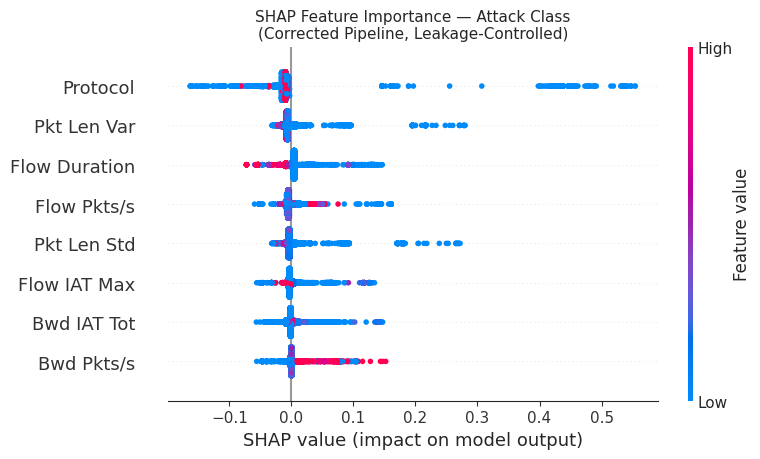

Saved: fig7_shap_corrected.pdf/.png

PROTOCOL FEATURE — LEAKAGE AUDIT
Protocol × Label distribution:


Label,0,1
Protocol,,
0,389,1024
6,31607,493
17,31700,3



Protocol × Label proportions:


Label,0,1
Protocol,,
0,0.275,0.725
6,0.985,0.015
17,1.000,0.000



it encodes capture session identity — not attack behaviour.
Discuss in paper under Section IV and Section V.

Number of False Negatives (Tuned RF): 4


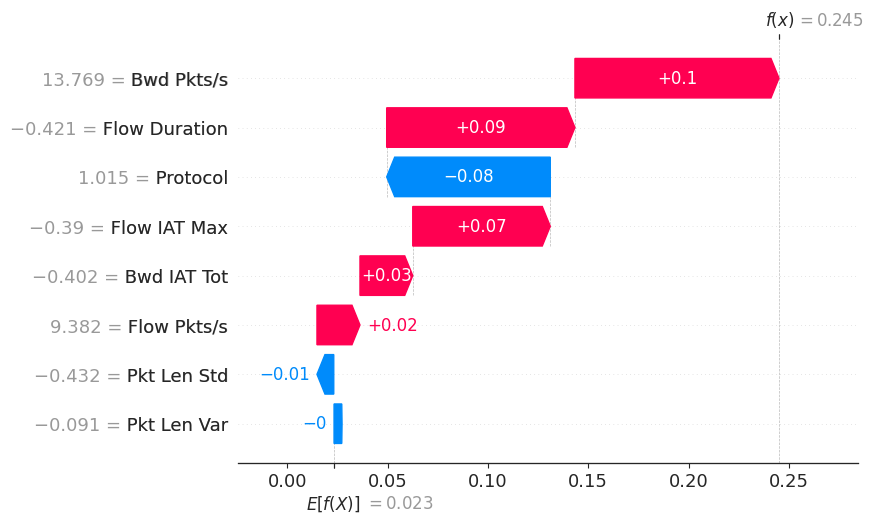

In [33]:
# ============================================================
# SHAP on Tuned RF from corrected pipeline.
# Supervisor: SHAP shows Protocol dominant but text says
# Flow Pkts/s and Flow Duration dominate — contradiction.
# Audit Protocol for capture-artifact leakage.
# ============================================================

# Retrieve the fitted RF from GridSearchCV pipeline
best_rf_fitted = grid_search_rf.best_estimator_.named_steps['clf']
_sc_shap = grid_search_rf.best_estimator_.named_steps['scaler']
X_test_sc_shap = pd.DataFrame(
    _sc_shap.transform(X_test_raw),
    columns=FEATURE_NAMES
)

print('Computing SHAP values (this may take a few minutes) ...')
explainer   = shap.TreeExplainer(best_rf_fitted)
shap_values = explainer.shap_values(X_test_sc_shap)

# Handle old/new SHAP output format
if isinstance(shap_values, list):
    shap_attack = shap_values[1]
else:
    shap_attack = (shap_values[:, :, 1]
                   if shap_values.ndim == 3 else shap_values)

# ── Global SHAP summary (corrected) ──────────────────────────
plt.figure(figsize=(8, 5))
shap.summary_plot(
    shap_attack, X_test_sc_shap,
    feature_names=FEATURE_NAMES, show=False
)
plt.title('SHAP Feature Importance — Attack Class\n'
          '(Corrected Pipeline, Leakage-Controlled)', fontsize=11)
plt.tight_layout()
plt.savefig('fig7_shap_corrected.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig7_shap_corrected.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig7_shap_corrected.pdf/.png')

# ── Protocol leakage audit ───────────────────────────────────
print('\n' + '='*60)
print('PROTOCOL FEATURE — LEAKAGE AUDIT')
print('='*60)

if 'Protocol' in df.columns:
    proto_tbl = df.groupby(['Protocol', 'Label']).size().unstack(fill_value=0)
    print('Protocol × Label distribution:')
    display(proto_tbl)
    proto_pct = proto_tbl.div(proto_tbl.sum(axis=1), axis=0)
    print('\nProtocol × Label proportions:')
    display(proto_pct.round(3))
    print('\nWARNING: If any Protocol value is 100% one class,')
    print('it encodes capture session identity — not attack behaviour.')
    print('Discuss in paper under Section IV and Section V.')
else:
    print('Protocol not in the 8-feature subset.')
    print('If SHAP still ranks it high, verify the feature names match.')

# ── False-negative SHAP force plots (first 5 FNs) ────────────
y_pred_shap = grid_search_rf.best_estimator_.predict(X_test_raw)
fn_indices  = np.where(
    (y_test_arr == 1) & (y_pred_shap == 0)
)[0]
print(f'\nNumber of False Negatives (Tuned RF): {len(fn_indices)}')

shap.initjs()
from IPython.display import HTML, display as ipy_display

for i, idx in enumerate(fn_indices[:3], 1):
    fp = shap.force_plot(
        explainer.expected_value[1],
        shap_attack[idx],
        X_test_sc_shap.iloc[idx],
        matplotlib=False
    )
    ipy_display(HTML(
        f'<h4>False Negative #{i} (test index {idx})</h4>'
        '<div style="background:white;padding:5px;overflow-x:auto;">'
        f'{fp.html()}</div>'
    ))

# Waterfall for first FN
if len(fn_indices) > 0:
    shap.waterfall_plot(
        shap.Explanation(
            values       = shap_attack[fn_indices[0]],
            base_values  = explainer.expected_value[1],
            data         = X_test_sc_shap.iloc[fn_indices[0]],
            feature_names= FEATURE_NAMES
        )
    )

## SECTION 21 — UMAP Visualization (Corrected Caption)

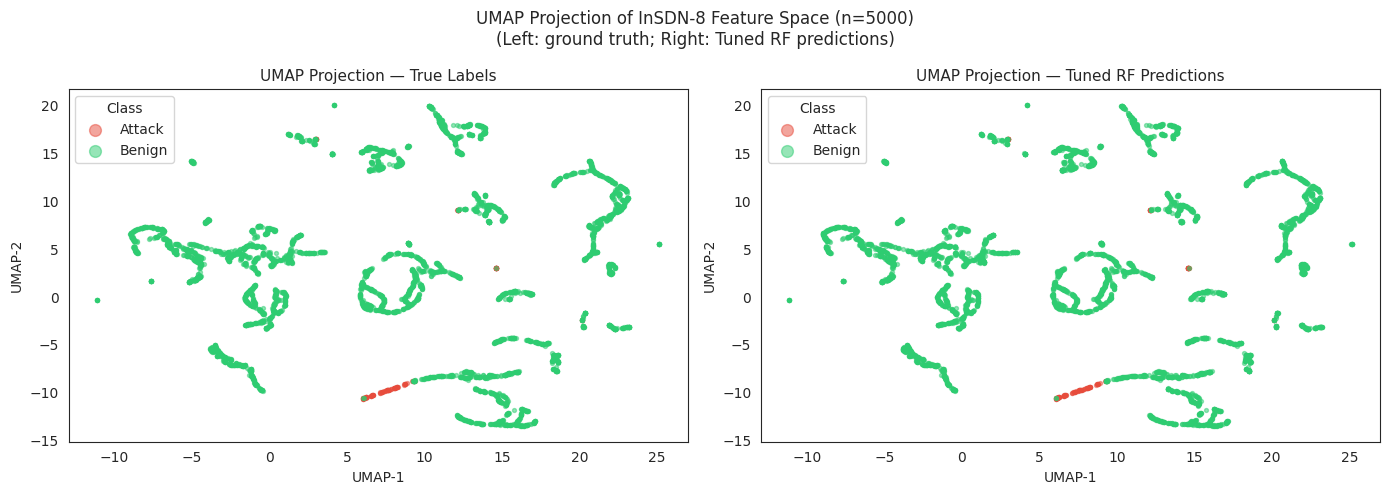

Saved: fig3_umap_twopanel.pdf/.png
IMPORTANT: Do NOT report silhouette on UMAP output.
Report silhouette in 8D space instead: 0.2919


In [34]:
# ============================================================
# UMAP — 2D projection for visualisation only.
# Supervisor: caption promised two-panel figure;
# figure showed one panel. Fix: produce both panels.
# Note: Silhouette score NOT reported on UMAP output.
# ============================================================
if UMAP_AVAILABLE:
    SAMPLE = 5000
    idx_s  = np.random.RandomState(RANDOM_SEED).choice(
        len(X_test_dl), SAMPLE, replace=False)
    X_samp = X_test_dl[idx_s]
    y_samp = y_test_arr[idx_s]
    y_pred_samp = y_pred_shap[idx_s]

    umap_model = UMAP(
        n_neighbors=15, min_dist=0.1,
        n_components=2, random_state=RANDOM_SEED
    )
    X_umap = umap_model.fit_transform(X_samp)

    umap_df = pd.DataFrame({
        'UMAP-1': X_umap[:, 0],
        'UMAP-2': X_umap[:, 1],
        'TrueLabel': ['Attack' if v == 1 else 'Benign' for v in y_samp],
        'PredLabel': ['Attack' if v == 1 else 'Benign' for v in y_pred_samp]
    })

    # Two-panel figure (as the caption promises)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    palette   = {'Benign': '#2ecc71', 'Attack': '#e74c3c'}

    for ax, col, title in zip(
            axes,
            ['TrueLabel', 'PredLabel'],
            ['True Labels', 'Tuned RF Predictions']):
        for label, grp in umap_df.groupby(col):
            ax.scatter(grp['UMAP-1'], grp['UMAP-2'],
                       c=palette[label], label=label,
                       s=8, alpha=0.5)
        ax.set_title(f'UMAP Projection — {title}', fontsize=11)
        ax.set_xlabel('UMAP-1'); ax.set_ylabel('UMAP-2')
        ax.legend(title='Class', markerscale=3)

    plt.suptitle(
        f'UMAP Projection of InSDN-8 Feature Space (n={SAMPLE})\n'
        '(Left: ground truth; Right: Tuned RF predictions)',
        fontsize=12
    )
    plt.tight_layout()
    plt.savefig('fig3_umap_twopanel.pdf', dpi=300, bbox_inches='tight')
    plt.savefig('fig3_umap_twopanel.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved: fig3_umap_twopanel.pdf/.png')
    print('IMPORTANT: Do NOT report silhouette on UMAP output.')
    print(f'Report silhouette in 8D space instead: {sil_score_8d:.4f}')
else:
    print('umap-learn not available. Install with: pip install umap-learn')

## SECTION 22 — All Paper Figures (ROC, Confusion Matrices, Latency, Performance Bar)

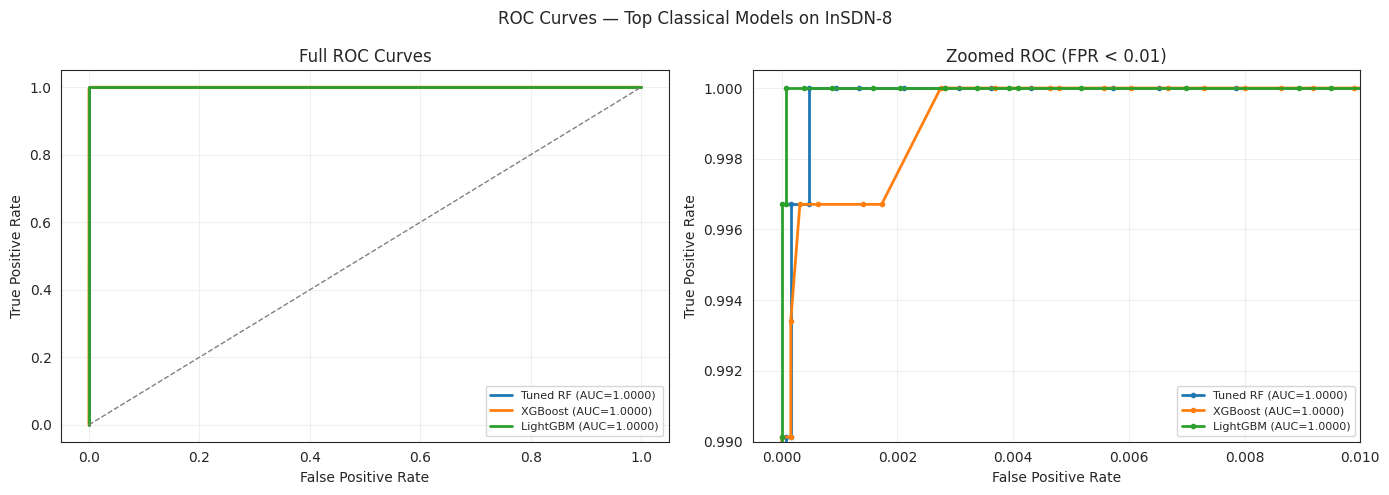

Saved: fig_roc_curves.pdf/.png


In [35]:
# ── ROC Curves ───────────────────────────────────────────────
# Collect probabilities for top classical models
roc_models = {
    'Tuned RF' : grid_search_rf.best_estimator_.predict_proba(X_test_raw)[:, 1],
    'XGBoost'  : xgb_pipe.predict_proba(X_test_raw)[:, 1],
    'LightGBM' : lgb_pipe.predict_proba(X_test_raw)[:, 1],
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, proba in roc_models.items():
    fpr, tpr, _ = roc_curve(y_test_arr, proba)
    auc_v = sk_auc(fpr, tpr)
    ax1.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc_v:.4f})')
    ax2.plot(fpr, tpr, linewidth=2, marker='o', markersize=3,
             markevery=0.05, label=f'{name} (AUC={auc_v:.4f})')

for ax in [ax1, ax2]:
    ax.plot([0,1],[0,1],'--', linewidth=1, color='grey')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(alpha=0.3)

ax1.set_title('Full ROC Curves')
ax2.set_title('Zoomed ROC (FPR < 0.01)')
ax2.set_xlim(-0.0005, 0.01)
ax2.set_ylim(0.990, 1.0005)

plt.suptitle('ROC Curves — Top Classical Models on InSDN-8', fontsize=12)
plt.tight_layout()
plt.savefig('fig_roc_curves.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig_roc_curves.pdf/.png')

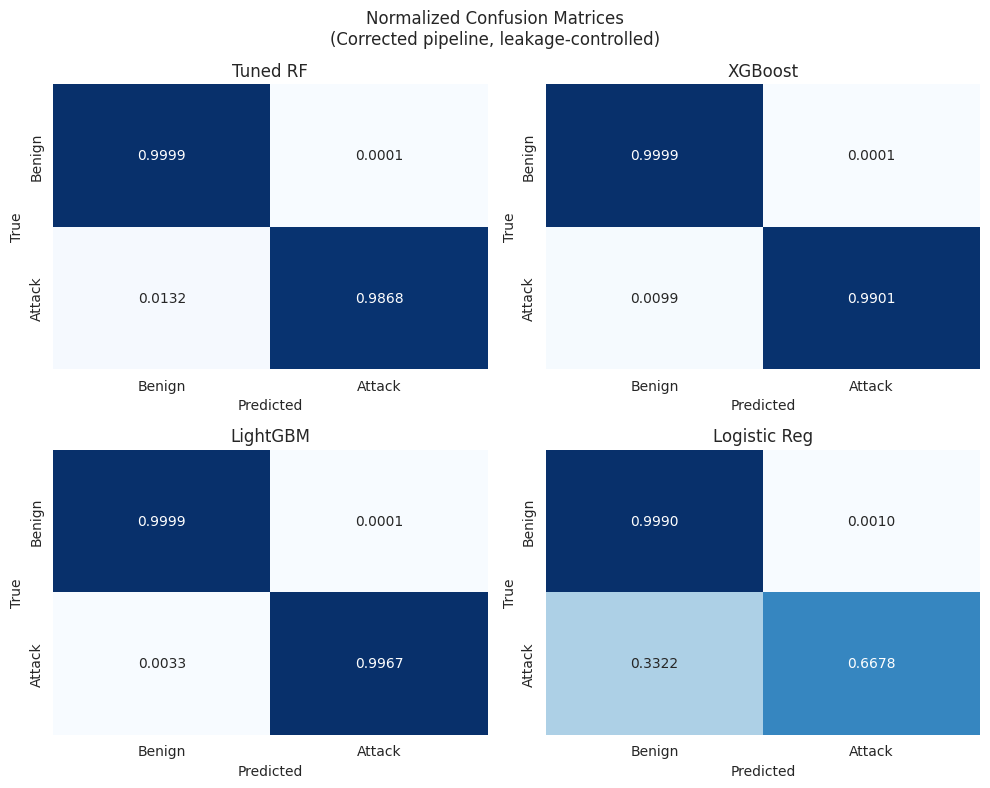

Saved: fig_confusion_matrices.pdf/.png


In [36]:
# ── Normalized Confusion Matrices (top 4 models) ────────────
top4_preds = {
    'Tuned RF'   : grid_search_rf.best_estimator_.predict(X_test_raw),
    'XGBoost'    : xgb_pipe.predict(X_test_raw),
    'LightGBM'   : lgb_pipe.predict(X_test_raw),
    'Logistic Reg': lr_pipe.predict(X_test_raw)
}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for ax, (name, preds) in zip(axes, top4_preds.items()):
    cm = confusion_matrix(y_test_arr, preds, normalize='true')
    sns.heatmap(
        cm, annot=True, fmt='.4f', cmap='Blues',
        ax=ax, cbar=False,
        xticklabels=['Benign', 'Attack'],
        yticklabels=['Benign', 'Attack']
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Normalized Confusion Matrices\n'
             '(Corrected pipeline, leakage-controlled)', fontsize=12)
plt.tight_layout()
plt.savefig('fig_confusion_matrices.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig_confusion_matrices.pdf/.png')

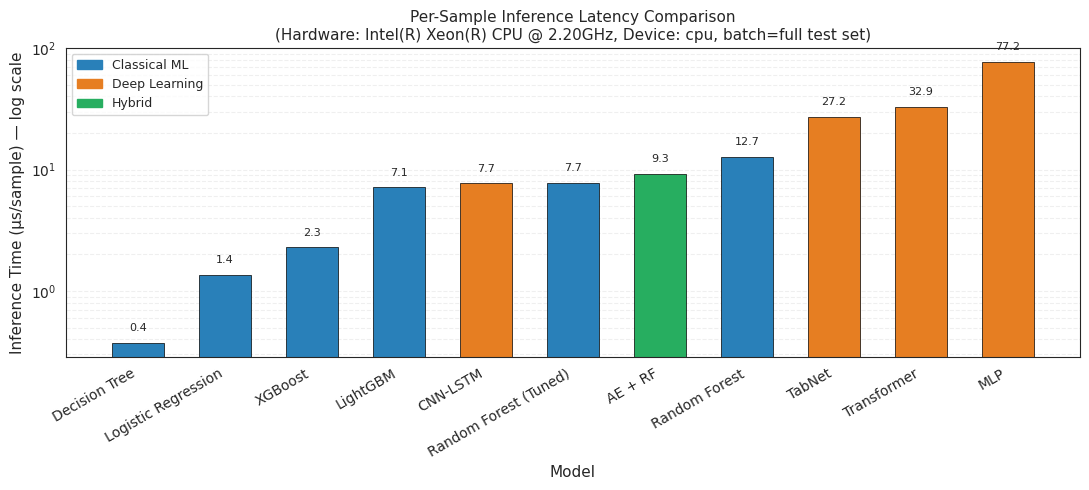

Saved: fig6_inference_latency.pdf/.png
This figure replaces the missing placeholder in the original paper.


In [37]:
# ── Fig 6: Inference Latency Bar Chart (was missing entirely) ─
lat_df = table2[['Model', 'Inf_Time_s']].dropna().copy()
lat_df = lat_df.sort_values('Inf_Time_s')

DL_MODELS = {'MLP', 'TabNet', 'Transformer', 'CNN-LSTM'}
HYB_MODELS = {'AE + RF'}

def model_color(name):
    if name in DL_MODELS:
        return '#e67e22'
    elif name in HYB_MODELS:
        return '#27ae60'
    return '#2980b9'

colors = [model_color(n) for n in lat_df['Model']]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(
    lat_df['Model'], lat_df['Inf_Time_s'] * 1e6,
    color=colors, edgecolor='black', linewidth=0.5, width=0.6
)
ax.set_yscale('log')
ax.set_ylabel('Inference Time (\u03bcs/sample) \u2014 log scale', fontsize=11)
ax.set_xlabel('Model', fontsize=11)

import subprocess
try:
    hw = subprocess.check_output(
        "lscpu | grep 'Model name'", shell=True
    ).decode().split(':')[1].strip()
except Exception:
    hw = platform.processor() or 'CPU model unavailable'
ax.set_title(
    f'Per-Sample Inference Latency Comparison\n'
    f'(Hardware: {hw}, Device: {DEVICE}, batch=full test set)',
    fontsize=11
)
plt.xticks(rotation=30, ha='right')

for bar, val in zip(bars, lat_df['Inf_Time_s'] * 1e6):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.2,
            f'{val:.1f}', ha='center', va='bottom', fontsize=8)

legend_patches = [
    mpatches.Patch(color='#2980b9', label='Classical ML'),
    mpatches.Patch(color='#e67e22', label='Deep Learning'),
    mpatches.Patch(color='#27ae60', label='Hybrid')
]
ax.legend(handles=legend_patches, loc='upper left', fontsize=9)
ax.grid(True, which='both', axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig6_inference_latency.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig6_inference_latency.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig6_inference_latency.pdf/.png')
print('This figure replaces the missing placeholder in the original paper.')

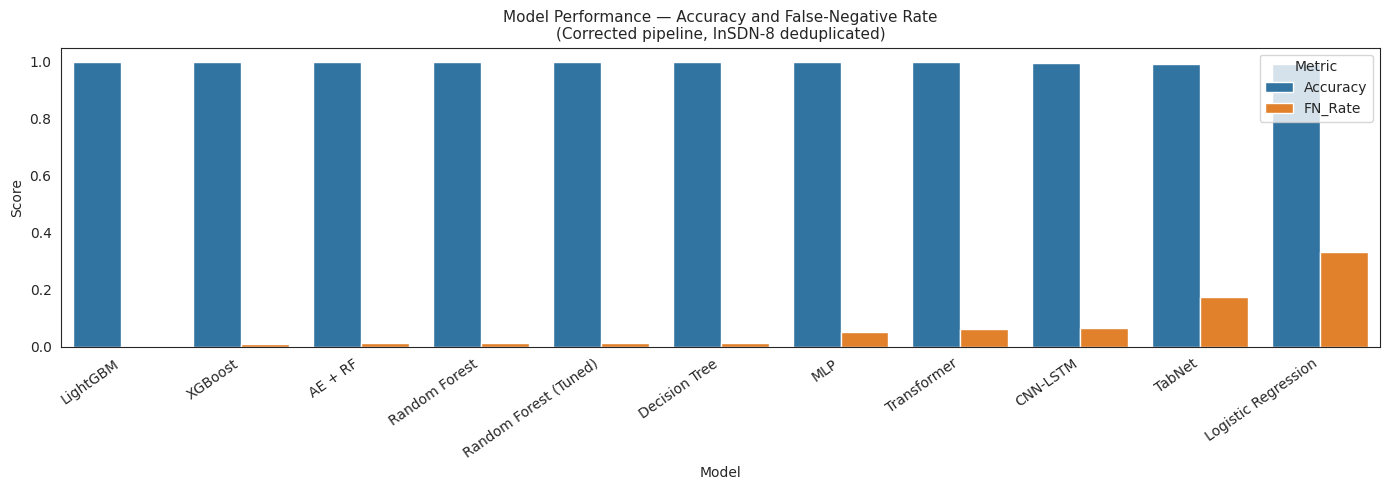

Saved: fig1_performance_comparison.pdf/.png
NOTE: p<0.01 caption claim REMOVED. See Section 17 for McNemar results.


In [38]:
# ── Performance Bar Chart (Accuracy + FN Rate) ───────────────
perf_df = table2[['Model', 'Accuracy', 'FN_Rate']].copy()
perf_df = perf_df.sort_values('Accuracy', ascending=False)
perf_melt = perf_df.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'FN_Rate'],
    var_name='Metric', value_name='Score'
)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(
    data=perf_melt, x='Model', y='Score',
    hue='Metric', ax=ax
)
ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_title('Model Performance — Accuracy and False-Negative Rate\n'
             '(Corrected pipeline, InSDN-8 deduplicated)', fontsize=11)
ax.set_ylabel('Score')
ax.legend(title='Metric', loc='upper right')
plt.tight_layout()
plt.savefig('fig1_performance_comparison.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig1_performance_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig1_performance_comparison.pdf/.png')
print('NOTE: p<0.01 caption claim REMOVED. See Section 17 for McNemar results.')

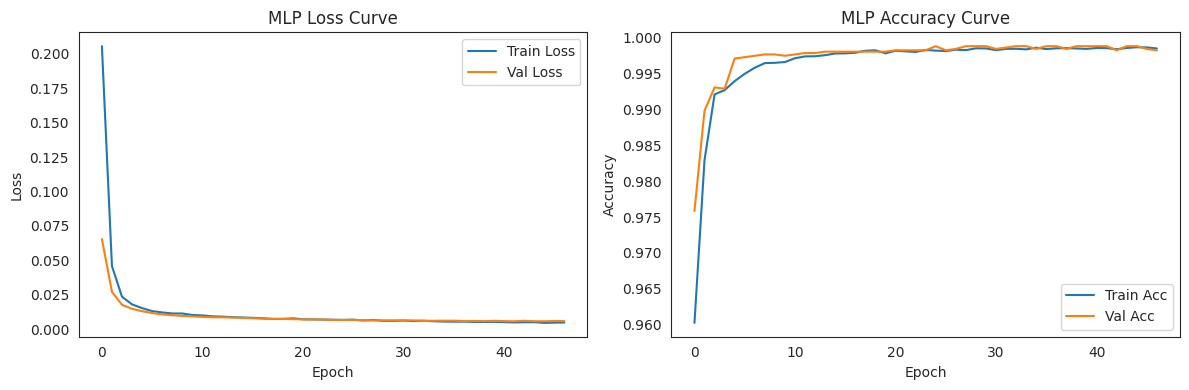

Saved: fig_mlp_training_curves.pdf/.png


In [39]:
# ── MLP Training Curves (for appendix / supplementary) ───────
# Retrain one MLP with verbose=1 to capture history
tf.random.set_seed(RANDOM_SEED)
mlp_vis = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu',
                          input_shape=(INPUT_DIM,)),
    tf.keras.layers.Dropout(0.2, seed=RANDOM_SEED),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
mlp_vis.compile(optimizer='adam',
                loss='binary_crossentropy', metrics=['accuracy'])
hist = mlp_vis.fit(
    X_train_dl, y_train_arr,
    validation_split=0.1,
    epochs=50, batch_size=256,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5,
        restore_best_weights=True)],
    verbose=0
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist.history['loss'],     label='Train Loss')
ax1.plot(hist.history['val_loss'], label='Val Loss')
ax1.set_title('MLP Loss Curve'); ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss'); ax1.legend()

ax2.plot(hist.history['accuracy'],     label='Train Acc')
ax2.plot(hist.history['val_accuracy'], label='Val Acc')
ax2.set_title('MLP Accuracy Curve'); ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy'); ax2.legend()

plt.tight_layout()
plt.savefig('fig_mlp_training_curves.pdf', dpi=300, bbox_inches='tight')
plt.savefig('fig_mlp_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()
print('Saved: fig_mlp_training_curves.pdf/.png')

## SECTION 23 — Final Summary & Reproducibility Report

In [40]:
!lscpu | grep 'Model name'

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


In [41]:
# ============================================================
# FINAL SUMMARY — print everything needed for paper sections
# ============================================================
print('=' * 80)
print('FINAL REPRODUCIBILITY REPORT')
print('=' * 80)

import sklearn, xgboost, lightgbm

print(f"\nLibrary versions:")
print(f"  Python      : {platform.python_version()}")
print(f"  NumPy       : {np.__version__}")
print(f"  Pandas      : {pd.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  XGBoost     : {xgboost.__version__}")
print(f"  LightGBM    : {lightgbm.__version__}")
print(f"  PyTorch     : {torch.__version__}")
print(f"  TensorFlow  : {tf.__version__}")
print(f"  SHAP        : {shap.__version__}")

print(f"\nHardware:")
import subprocess
try:
    cpu_model = subprocess.check_output(
        "lscpu | grep 'Model name'", shell=True
    ).decode().split(':')[1].strip()
except Exception:
    cpu_model = platform.processor() or 'CPU model unavailable'
print(f"  Platform    : {platform.platform()}")
print(f"  CPU Model   : {cpu_model}")
print(f"  Device      : {DEVICE}")

print(f"\nDataset:")
print(f"  CSV         : {CSV_PATH}")
print(f"  Total raw   : {AUDIT_RESULTS['total_raw']:,}")
print(f"  Exact dups  : {AUDIT_RESULTS['exact_dups']:,} "
      f"({AUDIT_RESULTS['dup_rate_pct']:.2f}%)")
print(f"  After dedup : {len(df):,}")
print(f"  Train       : {N_TRAIN:,}")
print(f"  Test        : {N_TEST:,}")
print(f"  Attack/test : {N_ATTACK_TEST:,}")
print(f"  Benign/test : {N_BENIGN_TEST:,}")
print(f"  Features    : {FEATURE_NAMES}")

print(f"\nTuned RF best params: {TUNED_RF_BEST_PARAMS}")

print(f"\nGroup-aware CV (Exp 5):")
print(f"  Grouping key : {group_col_final}")
print(f"  AUC  mean±σ  : {GA_AUC_MEAN:.4f} ± {GA_AUC_STD:.4f}")
print(f"  Recall mean±σ: {GA_RECALL_MEAN:.4f} ± {GA_RECALL_STD:.4f}")
print(f"  Acc  mean±σ  : {GA_ACC_MEAN:.4f} ± {GA_ACC_STD:.4f}")

print(f"\nSilhouette (8D standardised space): {sil_score_8d:.4f}")

print(f"\nLearning curve saturation:")
display(lc_df[['Fraction_pct', 'N_train', 'Test_Acc']])

# ── Fix: extract dict values before using in f-string ────────
best_stump_feature  = BEST_STUMP['Feature']
best_stump_accuracy = BEST_STUMP['Stump_Accuracy']
print(f"\nSingle-feature best stump: "
      f'"{best_stump_feature}" → {best_stump_accuracy:.6f}')

print(f"\n{'='*80}")
print('CORRECTED TABLE II (final — paste into paper)')
print(f"{'='*80}")

# Guard: build display_cols from what actually exists in table2
display_cols_safe = [
    c for c in [
        'Model', 'TP', 'TN', 'FP', 'FN',
        'Acc_±σ', 'Acc_[CI]',
        'Precision', 'Recall', 'F1',
        'FN_Rate', 'AUC', 'CV_AUC_±σ', 'Inf_Time_s'
    ]
    if c in table2.columns
]
display(table2[display_cols_safe])

print('\nAll output files generated:')
for fname in [
    'table2_corrected.csv',
    'fig_exp3_stump_baselines.pdf',
    'fig_exp4_learning_curve.pdf',
    'fig7_shap_corrected.pdf',
    'fig3_umap_twopanel.pdf',
    'fig_roc_curves.pdf',
    'fig_confusion_matrices.pdf',
    'fig6_inference_latency.pdf',
    'fig1_performance_comparison.pdf',
    'fig_mlp_training_curves.pdf',
    'dl_mlp_seed_results.csv',
    'dl_tabnet_seed_results.csv',
    'dl_transformer_seed_results.csv',
    'dl_cnn_lstm_seed_results.csv',
    'exp5_group_aware_cv_results.csv',
]:
    status = 'OK     ' if os.path.isfile(fname) else 'MISSING'
    print(f'  {status} {fname}')

FINAL REPRODUCIBILITY REPORT

Library versions:
  Python      : 3.13.15
  NumPy       : 2.1.3
  Pandas      : 2.2.3
  scikit-learn: 1.6.1
  XGBoost     : 3.4.1
  LightGBM    : 4.6.0
  PyTorch     : 2.11.0+cpu
  TensorFlow  : 2.20.0
  SHAP        : 0.52.0

Hardware:
  Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
  CPU Model   : Intel(R) Xeon(R) CPU @ 2.20GHz
  Device      : cpu

Dataset:
  CSV         : insdn8_ddos_binary_0n1d.csv
  Total raw   : 190,366
  Exact dups  : 125,150 (65.74%)
  After dedup : 65,216
  Train       : 52,172
  Test        : 13,044
  Attack/test : 304
  Benign/test : 12,740
  Features    : ['Protocol', 'Flow Duration', 'Flow IAT Max', 'Bwd Pkts/s', 'Pkt Len Std', 'Pkt Len Var', 'Bwd IAT Tot', 'Flow Pkts/s']

Tuned RF best params: {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}

Group-aware CV (Exp 5):
  Grouping key : Protocol × Flow Duration (q5)
  AUC  mean±σ  : 0.9856 ± 0.0232
  Recall mean±σ: 0.4967 ± 0.4879
  Acc  mean±σ 

,Fraction_pct,N_train,Test_Acc
0,0.5,260,0.983364
1,1.0,521,0.998390
2,5.0,2608,0.999310
3,10.0,5217,0.999157
4,25.0,13043,0.999310
5,50.0,26086,0.999387
6,100.0,52172,0.999693



Single-feature best stump: "Protocol" → 0.985894

CORRECTED TABLE II (final — paste into paper)


,Model,TP,TN,FP,FN,Acc_±σ,Acc_[CI],Precision,Recall,F1,FN_Rate,AUC,CV_AUC_±σ,Inf_Time_s
0,Logistic Regression,203,12727,13,101,0.9913,"0.9913 [0.9895, 0.9927]",0.939815,0.667763,0.780769,0.332237,0.973672,0.9760 ± 0.0048,1.359766e-06
1,Decision Tree,300,12736,4,4,0.9994,"0.9994 [0.9988, 0.9997]",0.986842,0.986842,0.986842,0.013158,0.993264,0.9912 ± 0.0063,3.732232e-07
2,Random Forest,300,12739,1,4,0.9996,"0.9996 [0.9991, 0.9998]",0.996678,0.986842,0.991736,0.013158,0.999997,1.0000 ± 0.0000,1.273487e-05
3,Random Forest (Tuned),300,12739,1,4,0.9996,"0.9996 [0.9991, 0.9998]",0.996678,0.986842,0.991736,0.013158,0.999997,1.0000 ± 0.0000,7.737107e-06
4,XGBoost,301,12739,1,3,0.9997,"0.9997 [0.9992, 0.9999]",0.996689,0.990132,0.993399,0.009868,0.999991,1.0000 ± 0.0000,2.289795e-06
5,LightGBM,303,12739,1,1,0.9998,"0.9998 [0.9994, 1.0000]",0.996711,0.996711,0.996711,0.003289,1.000000,1.0000 ± 0.0000,7.139919e-06
6,MLP,288,12735,5,16,0.9984 ± 0.0002,"0.9984 [0.9975, 0.9989]",0.983605,0.946710,0.964793,0.053290,0.998198,0.9993 ± 0.0006,7.715032e-05
7,TabNet,251,12719,21,53,0.9944 ± 0.0023,"0.9944 [0.9929, 0.9955]",0.931437,0.826316,0.867133,0.173684,0.998926,0.9976 ± 0.0019,2.716172e-05
8,Transformer,285,12737,3,19,0.9983 ± 0.0002,"0.9983 [0.9974, 0.9989]",0.990296,0.936842,0.962794,0.063158,0.999812,0.9996 ± 0.0003,3.286117e-05
9,CNN-LSTM,283,12734,6,21,0.9979 ± 0.0004,"0.9979 [0.9970, 0.9986]",0.978267,0.932237,0.954590,0.067763,0.999341,0.9976 ± 0.0014,7.716493e-06



All output files generated:
  OK      table2_corrected.csv
  OK      fig_exp3_stump_baselines.pdf
  OK      fig_exp4_learning_curve.pdf
  OK      fig7_shap_corrected.pdf
  OK      fig3_umap_twopanel.pdf
  OK      fig_roc_curves.pdf
  OK      fig_confusion_matrices.pdf
  OK      fig6_inference_latency.pdf
  OK      fig1_performance_comparison.pdf
  OK      fig_mlp_training_curves.pdf
  OK      dl_mlp_seed_results.csv
  OK      dl_tabnet_seed_results.csv
  OK      dl_transformer_seed_results.csv
  OK      dl_cnn_lstm_seed_results.csv
  OK      exp5_group_aware_cv_results.csv
